## 0. Configuration (edit this cell only)

In [22]:
import os, sys, re, gc, json, math, time, heapq, random, subprocess, warnings
from pathlib import Path
from dataclasses import dataclass, fields, asdict
from collections import Counter, OrderedDict

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", category=UserWarning)

# ----------------------------- environment -----------------------------
ON_KAGGLE = Path("/kaggle").exists()
WORK = Path("/kaggle/working") if ON_KAGGLE else Path("./lsi_work")
WORK.mkdir(parents=True, exist_ok=True)

# Phase 1 artifacts. NB: the enc-dec and the GQA checkpoints are BOTH called best_model.pt -> give the exact GQA path here.
PHASE1_CHECKPOINT_OVERRIDE = "/kaggle/input/datasets/vishwasp23/phase1-gqa/best_model.pt"      # <-- Phase 1 GQA decoder-only LM checkpoint (phase1_checkpoints/best_model.pt of the GQA notebook)
PHASE1_TOKENIZER_OVERRIDE  = "/kaggle/input/datasets/vishwasp23/tokenizer-p1/legal_bpe_a1_50k_final.json"
TOK_CACHE_OVERRIDE         = ""      # folder "lsi_tok_cache_v1" written by the exp-1 notebook (same tokenizer -> re-usable; saves ~20-30 min). "" = auto-discover, else rebuild.

# Data: either point to a local folder holding train.json/dev.json/test.json, or download from HF.
LOCAL_DATA_DIR = ""
HF_REPO_ID = "Exploration-Lab/CS-781-Capstone"
HF_FILES = {"train": "Phase_5_LSI/Train/train.json", "dev": "Phase_5_LSI/Train/dev.json", "test": "Phase_5_LSI/Test/test.json"}
# The token is read from env HF_TOKEN, then Kaggle Secret "HF_TOKEN", then a prompt. Never hard-code it.

NUM_LABELS = 100
MAX_LEN = 512                 # decoder context = the Phase 1 max_seq_len  ( </s> + 510 content + </s> )
CONTENT = MAX_LEN - 2
MAX_DOC_TOKENS = 16_384
TOK_CACHE_VERSION = "v1"

# ----------------------------- experiment budget -----------------------------
EXP_EPOCHS      = 2
EXP_TRAIN_DOCS  = 8_000
EXP_DEV_DOCS    = 3_000
MIN_POS_PER_LABEL_SUBSET = 60
EFFECTIVE_BATCH = 32
SELECTION_TOL   = 0.004       # parsimony rule: among configs within TOL of the best macro-F1, take the preferred/cheapest

# Which stages to run (a skipped stage keeps the BASE value below)
RUN_S0_LR, RUN_S1_LOSS, RUN_S2_HEAD, RUN_S3_REPR = False, False, True, True

# ----------------------------- final training -----------------------------
FINAL_MAX_EPOCHS    = 6
FINAL_PATIENCE      = 2           # early stopping on dev macro-F1 (global best threshold)
FINAL_TIME_BUDGET_H = 8.0         # planned epochs shrink so the LR schedule completes inside this budget (Kaggle session = 12 h)
RESUME_FINAL        = False

SMOKE_TEST = False                # True -> tiny end-to-end dry run to verify the whole pipeline
FINAL_TRAIN_DOCS_LIMIT = None

SEED = 42
BASE = dict(                      # starting recipe = exp-1 winners, with the proposed decoder readout
    views=("head",), view_agg="tokens", head="last_attn", loss="bce_posw",
    enc_lr=1e-4, head_lr=1e-3, llrd=0.92, wd=0.01, dropout=0.1, warmup=0.06,
)
EXP1_VIEWS_WINNER = ("head", "cue_rest")      # used if S3 is switched off

if SMOKE_TEST:
    EXP_TRAIN_DOCS, EXP_DEV_DOCS, FINAL_MAX_EPOCHS, FINAL_TRAIN_DOCS_LIMIT, MIN_POS_PER_LABEL_SUBSET = 256, 256, 2, 512, 2
RUN_DIR = WORK / ("lsi_gqa_runs_smoke" if SMOKE_TEST else "lsi_gqa_runs"); RUN_DIR.mkdir(parents=True, exist_ok=True)
EXP_STORE = RUN_DIR / "experiments.json"

def discover_cache():
    need = ["train_done.flag", "dev_done.flag", "test_done.flag"]; cands = []
    if TOK_CACHE_OVERRIDE: cands.append(Path(TOK_CACHE_OVERRIDE))
    cands.append(WORK / f"lsi_tok_cache_{TOK_CACHE_VERSION}")
    if Path("/kaggle/input").exists():
        try: cands += [p.parent for p in Path("/kaggle/input").rglob("train_done.flag")]
        except Exception: pass
    for c in cands:
        if all((c / f).exists() for f in need): return c, True
    return WORK / f"lsi_tok_cache_{TOK_CACHE_VERSION}", False
CACHE_DIR, CACHE_READY = discover_cache()
if not CACHE_READY: CACHE_DIR.mkdir(parents=True, exist_ok=True)
print("WORK:", WORK.resolve(), "| ON_KAGGLE:", ON_KAGGLE)
print("token cache:", CACHE_DIR, "(ready)" if CACHE_READY else "(will be built)")

WORK: /kaggle/working | ON_KAGGLE: True
token cache: /kaggle/working/lsi_tok_cache_v1 (ready)


## 1. Imports, GPU, seeds

In [2]:
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.checkpoint import checkpoint
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm
try:
    from IPython.display import display
except Exception:
    display = print

def seed_everything(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
seed_everything(SEED)

assert torch.cuda.is_available(), "Enable a GPU runtime."
device = torch.device("cuda")
gpu = torch.cuda.get_device_properties(0)
print("GPU:", gpu.name, f"| {gpu.total_memory/1024**3:.1f} GiB | torch {torch.__version__}")

GPU: Tesla T4 | 14.6 GiB | torch 2.11.0+cu128


## 2. Locate / download the Phase 5 data and the Phase 1 artifacts

In [3]:
try:
    import ijson
except ImportError:
    try:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ijson"]); import ijson
    except Exception:
        ijson = None

def _get_hf_token():
    tok = os.environ.get("HF_TOKEN", "").strip()
    if not tok:
        try:
            from kaggle_secrets import UserSecretsClient
            tok = UserSecretsClient().get_secret("HF_TOKEN")
        except Exception:
            tok = ""
    if not tok:
        from getpass import getpass
        tok = getpass("Hugging Face token: ")
    return tok

def locate_data():
    paths = {}
    if LOCAL_DATA_DIR:
        for split in HF_FILES:
            p = Path(LOCAL_DATA_DIR) / f"{split}.json"
            if not p.is_file(): raise FileNotFoundError(p)
            paths[split] = p
        return paths
    from huggingface_hub import hf_hub_download
    token = _get_hf_token()
    for split, fn in HF_FILES.items():
        paths[split] = Path(hf_hub_download(repo_id=HF_REPO_ID, repo_type="dataset", filename=fn, token=token))
    return paths

def iter_json_records(path):
    """Yield records from a JSON array (streamed with ijson when available) or JSONL."""
    with open(path, "rb") as f:
        first = b""
        while True:
            ch = f.read(1)
            if not ch: break
            if ch not in b" \t\r\n": first = ch; break
        f.seek(0)
        if first == b"[":
            if ijson is not None:
                yield from ijson.items(f, "item")
            else:
                yield from json.load(f)
        elif first == b"{":
            for line in f:
                line = line.strip()
                if line: yield json.loads(line)
        else:
            raise ValueError(f"Unrecognised JSON layout: {path}")

def find_artifact(filename, override=""):
    if override and Path(override).is_file(): return Path(override).resolve()
    hits = set()
    for root in [Path("/kaggle/input"), WORK, Path(".")]:
        if root.exists(): hits.update(p.resolve() for p in root.rglob(filename) if p.is_file())
    hits = sorted(hits)
    if len(hits) != 1:
        raise FileNotFoundError(f"{filename}: found {len(hits)} candidates {hits}. Set the override path in the config cell.")
    return hits[0]


need_raw = not CACHE_READY
paths = locate_data() if need_raw else {}
PHASE1_TOKENIZER_PATH  = find_artifact("legal_bpe_a1_50k_final.json", PHASE1_TOKENIZER_OVERRIDE)
PHASE1_CHECKPOINT_PATH = find_artifact("best_model.pt", PHASE1_CHECKPOINT_OVERRIDE)
print("data paths :", {k: str(v) for k, v in paths.items()} if paths else "(token cache present, raw files not needed)")
print("tokenizer  :", PHASE1_TOKENIZER_PATH); print("checkpoint :", PHASE1_CHECKPOINT_PATH)

Hugging Face token:  ········


Phase_5_LSI/Train/train.json: reconstructing file:   0%|          |  0.00B /  299MB            

Phase_5_LSI/Train/train.json: downloading bytes:           |  0.00B            

Phase_5_LSI/Train/dev.json: reconstructing file:   0%|          |  0.00B / 79.4MB            

Phase_5_LSI/Train/dev.json: downloading bytes:           |  0.00B            

Phase_5_LSI/Test/test.json: reconstructing file:   0%|          |  0.00B / 98.1MB            

Phase_5_LSI/Test/test.json: downloading bytes:           |  0.00B            

data paths : {'train': '/root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/93b0059be756c6c461f3a225de25aabda7d5f84a/Phase_5_LSI/Train/train.json', 'dev': '/root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/93b0059be756c6c461f3a225de25aabda7d5f84a/Phase_5_LSI/Train/dev.json', 'test': '/root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/93b0059be756c6c461f3a225de25aabda7d5f84a/Phase_5_LSI/Test/test.json'}
tokenizer  : /kaggle/input/datasets/vishwasp23/tokenizer-p1/legal_bpe_a1_50k_final.json
checkpoint : /kaggle/input/datasets/vishwasp23/phase1-gqa/best_model.pt


## 3. Phase 1 tokenizer (identical A-1 BPE) and the Phase 1 **GQA decoder** (same parameter names as the Phase 1 notebook → weights load 1 : 1)

In [4]:
SPECIAL_TOKENS = ["<pad>", "<unk>", "<s>", "</s>"]
N_SPECIAL, N_BYTES = 4, 256
BASE_VOCAB = N_SPECIAL + N_BYTES
WORD_RE = re.compile(r"\S+")

class A1BPETokenizer:
    def __init__(self, itos, merges):
        self.itos = list(itos); self.merges = [tuple(m) for m in merges]
        self.vocab_size = len(self.itos)
        self.stoi = {s: i for i, s in enumerate(self.itos)}
        self._byte_to_id = {bytes([b]): N_SPECIAL + b for b in range(256)}
        self._merge_ranks = {pair: r for r, pair in enumerate(self.merges)}

    def _encode_word(self, word):                      # unchanged from Phase 1 / Phase 3
        raw = word.encode("utf-8")
        seq = [self._byte_to_id[bytes([b])] for b in raw]
        if len(seq) < 2 or not self._merge_ranks: return seq
        n = len(seq); prev = [-1] + list(range(n - 1)); nxt = list(range(1, n)) + [-1]
        active = [True] * n; heap = []
        for i in range(n - 1):
            r = self._merge_ranks.get((seq[i], seq[i + 1]))
            if r is not None: heapq.heappush(heap, (r, i, i + 1))
        while heap:
            rank, left, right = heapq.heappop(heap)
            if not active[left] or not active[right]: continue
            if nxt[left] != right or prev[right] != left: continue
            if self._merge_ranks.get((seq[left], seq[right])) != rank: continue
            seq[left] = BASE_VOCAB + rank; active[right] = False
            rn = nxt[right]; nxt[left] = rn
            if rn != -1: prev[rn] = left
            lp = prev[left]
            if lp != -1:
                nr = self._merge_ranks.get((seq[lp], seq[left]))
                if nr is not None: heapq.heappush(heap, (nr, lp, left))
            if rn != -1:
                nr = self._merge_ranks.get((seq[left], seq[rn]))
                if nr is not None: heapq.heappush(heap, (nr, left, rn))
        out, i = [], 0
        while i != -1:
            if active[i]: out.append(seq[i])
            i = nxt[i]
        return out

def load_a1_tokenizer(path):
    with open(path, "r", encoding="utf-8") as f: payload = json.load(f)
    tok = A1BPETokenizer(payload["itos"], payload["merges"])
    assert tok.vocab_size == 50_000 and tok.itos[:4] == SPECIAL_TOKENS
    return tok

phase1_tokenizer = load_a1_tokenizer(PHASE1_TOKENIZER_PATH)
PAD_ID, UNK_ID, BOS_ID, EOS_ID = 0, 1, 2, 3
SPACE_ID = N_SPECIAL + 32          # single ASCII space byte token (id 36)
assert (phase1_tokenizer.stoi["<pad>"], phase1_tokenizer.stoi["<s>"], phase1_tokenizer.stoi["</s>"]) == (0, 2, 3)


@dataclass
class ModelConfig:
    vocab_size: int = 50_000; d_model: int = 768; n_layers: int = 16; n_heads: int = 12
    n_kv_heads: int = 4; d_ff: int = 2048; max_seq_len: int = 512
    rope_base: float = 10_000.0; rms_norm_eps: float = 1e-6; dropout: float = 0.0

def build_rope_cache(max_seq_len, d_head, base=10_000.0):
    inv_freq = 1.0 / (base ** (torch.arange(0, d_head // 2, dtype=torch.float32) * 2 / d_head))
    freqs = torch.outer(torch.arange(max_seq_len, dtype=torch.float32), inv_freq)
    ang = torch.cat([freqs, freqs], dim=-1)
    return ang.cos(), ang.sin()

def rotate_half(x):
    x1, x2 = torch.chunk(x, 2, dim=-1)
    return torch.cat([-x2, x1], dim=-1)

def apply_rope(x, cos, sin):
    return x * cos.to(x.device, x.dtype)[None, None] + rotate_half(x) * sin.to(x.device, x.dtype)[None, None]

class RMSNorm(nn.Module):
    def __init__(self, dim, eps=1e-6):
        super().__init__(); self.eps = eps; self.weight = nn.Parameter(torch.ones(dim))
    def forward(self, x):
        dt = x.dtype; xf = x.float()
        return (xf * torch.rsqrt(xf.pow(2).mean(-1, keepdim=True) + self.eps) * self.weight.float()).to(dt)

class SwiGLU(nn.Module):
    def __init__(self, d, ff):
        super().__init__()
        self.gate_proj = nn.Linear(d, ff, bias=False); self.up_proj = nn.Linear(d, ff, bias=False)
        self.down_proj = nn.Linear(ff, d, bias=False)
    def forward(self, x): return self.down_proj(F.silu(self.gate_proj(x)) * self.up_proj(x))


class CausalGQAAttention(nn.Module):
    """Phase 1 CausalSelfAttention (no KV-cache needed for classification); fused SDPA with a causal mask."""
    def __init__(self, c):
        super().__init__()
        self.d_model, self.n_heads, self.n_kv_heads = c.d_model, c.n_heads, c.n_kv_heads
        self.head_dim = c.d_model // c.n_heads; self.n_rep = c.n_heads // c.n_kv_heads; self.max_seq_len = c.max_seq_len
        self.q_proj = nn.Linear(c.d_model, c.n_heads * self.head_dim, bias=False)
        self.k_proj = nn.Linear(c.d_model, c.n_kv_heads * self.head_dim, bias=False)
        self.v_proj = nn.Linear(c.d_model, c.n_kv_heads * self.head_dim, bias=False)
        self.out_proj = nn.Linear(c.d_model, c.d_model, bias=False)
        cos, sin = build_rope_cache(c.max_seq_len, self.head_dim, c.rope_base)
        self.register_buffer("rope_cos", cos, persistent=False); self.register_buffer("rope_sin", sin, persistent=False)
    def _split(self, x, n):
        b, t, _ = x.shape
        return x.reshape(b, t, n, self.head_dim).transpose(1, 2)
    def forward(self, x):
        b, t, _ = x.shape
        if t > self.max_seq_len: raise ValueError(f"sequence {t} > {self.max_seq_len}")
        q = apply_rope(self._split(self.q_proj(x), self.n_heads), self.rope_cos[:t], self.rope_sin[:t])
        k = apply_rope(self._split(self.k_proj(x), self.n_kv_heads), self.rope_cos[:t], self.rope_sin[:t])
        v = self._split(self.v_proj(x), self.n_kv_heads)
        k = k.repeat_interleave(self.n_rep, dim=1); v = v.repeat_interleave(self.n_rep, dim=1)
        a = F.scaled_dot_product_attention(q, k, v, dropout_p=0.0, is_causal=True)
        return self.out_proj(a.transpose(1, 2).contiguous().view(b, t, self.d_model))

class DecoderBlock(nn.Module):                      # names = Phase 1 TransformerBlock: norm1 / attn / norm2 / mlp
    def __init__(self, c):
        super().__init__()
        self.norm1 = RMSNorm(c.d_model, c.rms_norm_eps); self.attn = CausalGQAAttention(c)
        self.norm2 = RMSNorm(c.d_model, c.rms_norm_eps); self.mlp = SwiGLU(c.d_model, c.d_ff)
    def forward(self, x):
        x = x + self.attn(self.norm1(x))
        return x + self.mlp(self.norm2(x))

class DecoderBackbone(nn.Module):
    """Phase 1 LegalDecoderLM without the LM head: token ids -> hidden states after the (pre-trained) final RMSNorm."""
    def __init__(self, c, grad_ckpt=True):
        super().__init__(); self.config = c; self.grad_ckpt = grad_ckpt
        self.token_embedding = nn.Embedding(c.vocab_size, c.d_model)
        self.blocks = nn.ModuleList([DecoderBlock(c) for _ in range(c.n_layers)])
        self.final_norm = RMSNorm(c.d_model, c.rms_norm_eps)
    def forward(self, input_ids):
        x = self.token_embedding(input_ids)
        for blk in self.blocks:
            x = checkpoint(blk, x, use_reentrant=False) if (self.grad_ckpt and self.training and torch.is_grad_enabled()) else blk(x)
        return self.final_norm(x)

# ---- Phase 1 checkpoint (GQA decoder-only LM)
_ckpt = torch.load(PHASE1_CHECKPOINT_PATH, map_location="cpu", weights_only=False)
_cfg_dict = dict(_ckpt["model_config"]); PHASE1_STATE = {}
for _k, _v in _ckpt["model_state_dict"].items():
    for _pre in ("module.", "_orig_mod."):
        if _k.startswith(_pre): _k = _k[len(_pre):]
    PHASE1_STATE[_k] = _v
assert "blocks.0.attn.q_proj.weight" in PHASE1_STATE and "decoder_blocks.0.norm1.weight" not in PHASE1_STATE, \
    "this is not the GQA decoder-only checkpoint (is it the encoder-decoder best_model.pt?) -> set PHASE1_CHECKPOINT_OVERRIDE"
PHASE1_STATE.pop("lm_head.weight", None)                     # tied to token_embedding
cfg = ModelConfig(**{k: v for k, v in _cfg_dict.items() if k in {f.name for f in fields(ModelConfig)}})
print("Phase 1 GQA checkpoint:", {k: v for k, v in _ckpt.items() if k in ("global_step", "tokens_seen", "best_val_loss")}); del _ckpt; gc.collect()
print(cfg)
assert cfg.vocab_size == phase1_tokenizer.vocab_size and cfg.max_seq_len >= MAX_LEN, "tokenizer / context mismatch with the checkpoint"
D_MODEL = cfg.d_model

def load_phase1_decoder_weights(m, state):
    res = m.load_state_dict(state, strict=True); return res
_probe = DecoderBackbone(cfg, grad_ckpt=False); load_phase1_decoder_weights(_probe, PHASE1_STATE)
BACKBONE_PARAMS = sum(p.numel() for p in _probe.parameters()); del _probe
print(f"decoder backbone parameters: {BACKBONE_PARAMS/1e6:.2f} M (weights loaded with strict=True)")

Phase 1 GQA checkpoint: {'global_step': 15000, 'tokens_seen': 491651072, 'best_val_loss': 1.4796594381332397}
ModelConfig(vocab_size=50000, d_model=768, n_layers=16, n_heads=12, n_kv_heads=4, d_ff=2048, max_seq_len=512, rope_base=10000.0, rms_norm_eps=1e-06, dropout=0.0)
decoder backbone parameters: 139.09 M (weights loaded with strict=True)


## 4. Token cache — the exp-1 cache is re-used when found (same tokenizer), otherwise built once

In [5]:
CUE_RE = re.compile(r"<(?:SECTION|ACT)>|^(?:[Ss]ections?|[Ss]ec\.?|[Aa]rticles?|[Rr]ules?|[Aa]ct|[Aa]cts|IPC|CrPC|Cr\.P\.C\.?|Code)\W*$")
SENT_END_CHARS = (".", ";", "?", "!", ":")
FLAG_CUE, FLAG_SENT = 1, 2

class FastDocTokenizer:
    """Word-level cached version of the Phase 1 tokenizer. Output ids are identical to the original encoder
    except runs of whitespace between words are collapsed to ONE space token and leading/trailing whitespace is dropped."""
    def __init__(self, tok, max_doc_tokens=MAX_DOC_TOKENS, tail_keep=4096, cache_limit=3_000_000):
        self.tok, self.max_doc_tokens, self.tail_keep, self.cache_limit = tok, max_doc_tokens, tail_keep, cache_limit
        self.cache = {}
    def _word(self, w):
        r = self.cache.get(w)
        if r is None:
            ids = self.tok._encode_word(w)
            fl = [0] * len(ids)
            if CUE_RE.search(w): fl[0] |= FLAG_CUE
            if w.endswith(SENT_END_CHARS): fl[-1] |= FLAG_SENT
            r = (tuple(ids), tuple(fl))
            if len(self.cache) > self.cache_limit: self.cache.clear()
            self.cache[w] = r
        return r
    def encode(self, text):
        ids, fl, cursor, first = [], [], 0, True
        for m in WORD_RE.finditer(text):
            if not first: ids.append(SPACE_ID); fl.append(0)
            w_ids, w_fl = self._word(m.group(0)); ids.extend(w_ids); fl.extend(w_fl); first = False
        n = len(ids)
        if n > self.max_doc_tokens:
            cut = self.max_doc_tokens - self.tail_keep
            ids = ids[:cut] + ids[-self.tail_keep:]; fl = fl[:cut] + fl[-self.tail_keep:]
        return np.asarray(ids, dtype=np.uint16), np.asarray(fl, dtype=np.uint8), n

_WORKER = {}
def _init_worker():
    _WORKER["t"] = FastDocTokenizer(phase1_tokenizer)
def _tok_batch(texts):
    t = _WORKER["t"]; out = []
    for s in texts:
        i, f, n = t.encode(s); out.append((i, f, n))
    return out

def build_split_cache(split):
    flag = CACHE_DIR / f"{split}_done.flag"
    if flag.exists(): return
    has_labels = split != "test"
    ids_raw, texts, labels = [], [], []
    for row in tqdm(iter_json_records(paths[split]), desc=f"read {split}"):
        ids_raw.append(row["id"]); texts.append(row["text"])
        if has_labels:
            lab = sorted(set(int(x) for x in row["labels"]))
            assert all(0 <= x < NUM_LABELS for x in lab), f"bad label in {row['id']}"
            labels.append(lab)
    n_docs = len(texts)
    batches = [texts[i:i + 128] for i in range(0, n_docs, 128)]
    results = []
    try:
        import multiprocessing as mp
        ctx = mp.get_context("fork"); nproc = min(4, os.cpu_count() or 1)
        with ctx.Pool(nproc, initializer=_init_worker) as pool:
            for r in tqdm(pool.imap(_tok_batch, batches), total=len(batches), desc=f"tokenise {split}"):
                results.extend(r)
    except Exception as e:
        print("parallel tokenisation unavailable (", type(e).__name__, ") -> sequential"); _init_worker()
        results = []
        for b in tqdm(batches, desc=f"tokenise {split} (seq)"): results.extend(_tok_batch(b))
    lengths = np.array([len(r[0]) for r in results], dtype=np.int64)
    offsets = np.zeros(n_docs + 1, dtype=np.int64); offsets[1:] = np.cumsum(lengths)
    np.save(CACHE_DIR / f"{split}_tokens.npy", np.concatenate([r[0] for r in results]))
    np.save(CACHE_DIR / f"{split}_flags.npy",  np.concatenate([r[1] for r in results]))
    np.save(CACHE_DIR / f"{split}_offsets.npy", offsets)
    np.save(CACHE_DIR / f"{split}_orig_len.npy", np.array([r[2] for r in results], dtype=np.int64))
    if has_labels:
        Y = np.zeros((n_docs, NUM_LABELS), dtype=np.uint8)
        for i, lab in enumerate(labels): Y[i, lab] = 1
        np.save(CACHE_DIR / f"{split}_labels.npy", Y)
    with open(CACHE_DIR / f"{split}_case_ids.json", "w", encoding="utf-8") as f: json.dump(ids_raw, f)
    flag.write_text("ok"); del results, texts; gc.collect()
    print(f"{split}: {n_docs:,} docs | {lengths.sum():,} tokens | mean {lengths.mean():.0f} | median {np.median(lengths):.0f}")

t0 = time.time()
for s in ["train", "dev", "test"]: build_split_cache(s)
print(f"token cache ready in {(time.time()-t0)/60:.1f} min  ->  {CACHE_DIR}")

read train: 0it [00:00, ?it/s]

tokenise train:   0%|          | 0/334 [00:00<?, ?it/s]

train: 42,750 docs | 102,823,711 tokens | mean 2405 | median 988


read dev: 0it [00:00, ?it/s]

tokenise dev:   0%|          | 0/80 [00:00<?, ?it/s]

dev: 10,181 docs | 27,323,268 tokens | mean 2684 | median 1247


read test: 0it [00:00, ?it/s]

tokenise test:   0%|          | 0/102 [00:00<?, ?it/s]

test: 13,019 docs | 33,541,917 tokens | mean 2576 | median 1227
token cache ready in 0.9 min  ->  /kaggle/working/lsi_tok_cache_v1


### 4b. Load cached arrays + label statistics

In [6]:
def load_arrays(split, has_labels=True):
    d = dict(tokens=np.load(CACHE_DIR / f"{split}_tokens.npy", mmap_mode="r"),
             flags=np.load(CACHE_DIR / f"{split}_flags.npy", mmap_mode="r"),
             offsets=np.load(CACHE_DIR / f"{split}_offsets.npy"),
             orig_len=np.load(CACHE_DIR / f"{split}_orig_len.npy"))
    d["ids"] = json.load(open(CACHE_DIR / f"{split}_case_ids.json"))
    if has_labels: d["labels"] = np.load(CACHE_DIR / f"{split}_labels.npy")
    return d

ARR = {"train": load_arrays("train"), "dev": load_arrays("dev"), "test": load_arrays("test", has_labels=False)}
for s, a in ARR.items():
    L = np.diff(a["offsets"])
    cue = np.array([int((np.asarray(a["flags"][a["offsets"][i]:a["offsets"][i+1]]) & FLAG_CUE).sum()) for i in range(0, len(L), max(1, len(L)//2000))])
    print(f"{s:5s} docs={len(L):6,d} | tokens p50={np.percentile(L,50):.0f} p90={np.percentile(L,90):.0f} p99={np.percentile(L,99):.0f}"
          f" | >510 tok: {(L>CONTENT).mean()*100:.1f}% | >1020 tok: {(L>2*CONTENT).mean()*100:.1f}% | cue words/doc (sample) mean={cue.mean():.1f}")
Ytr, Ydv = ARR["train"]["labels"], ARR["dev"]["labels"]
print("labels/doc train: mean %.2f | positives per label min/median/max = %d/%d/%d" % (Ytr.sum(1).mean(), Ytr.sum(0).min(), np.median(Ytr.sum(0)), Ytr.sum(0).max()))
PRIOR = np.clip(Ytr.mean(0), 1e-5, 1 - 1e-5)                 # label prior (train) used for bias init and class weights
POS_COUNT = Ytr.sum(0).astype(np.float64)

train docs=42,750 | tokens p50=988 p90=6383 p99=16384 | >510 tok: 70.9% | >1020 tok: 49.1% | cue words/doc (sample) mean=11.5
dev   docs=10,181 | tokens p50=1247 p90=6885 p99=16384 | >510 tok: 73.2% | >1020 tok: 55.2% | cue words/doc (sample) mean=12.5
test  docs=13,019 | tokens p50=1227 p90=6538 p99=16384 | >510 tok: 73.6% | >1020 tok: 54.8% | cue words/doc (sample) mean=12.1
labels/doc train: mean 3.70 | positives per label min/median/max = 272/679/11730


## 5. Document views — windows of the form `[</s>] + ≤510 text tokens + [</s>]`

The `head`, `tail`, `headtail`, `cue`, `cue_rest` view builders are the ones of experiment 1. The only change is the framing of every window: the **leading and trailing token are both `</s>`** (instead of `<s>` … `</s>`), as in the Phase 1 pre-training stream.

In [7]:
MAX_SEG = 96            # long "sentences" are cut into pieces of at most this many tokens
CUE_CAP = 3             # a segment's cue score saturates at this many cue words
LAST_BONUS_TOKENS = 128 # segments inside the last 128 tokens get a small bonus (operative part)

def select_cue_tokens(tok, fl, budget=CONTENT, head_keep=128):
    """Relevance-based context selection. tok/fl: uint16/uint8 arrays of the (sub)document."""
    n = len(tok)
    if n <= budget: return tok
    head = tok[:head_keep]; rest = tok[head_keep:]; rfl = fl[head_keep:]; budget_rest = budget - len(head)
    nr = len(rest)
    ends = np.flatnonzero(rfl & FLAG_SENT) + 1
    bounds = [0] + ends.tolist()
    if bounds[-1] != nr: bounds.append(nr)
    starts_l, ends_l = [], []
    for a, b in zip(bounds[:-1], bounds[1:]):
        while b - a > MAX_SEG:
            starts_l.append(a); ends_l.append(a + MAX_SEG); a += MAX_SEG
        if b > a: starts_l.append(a); ends_l.append(b)
    starts = np.asarray(starts_l); ends_a = np.asarray(ends_l)
    cs = np.concatenate([[0], np.cumsum((rfl & FLAG_CUE).astype(np.int64))])
    score = np.minimum(cs[ends_a] - cs[starts], CUE_CAP).astype(np.float64)
    score += 0.5 * (starts >= nr - LAST_BONUS_TOKENS)
    score -= np.arange(len(starts)) * 1e-6                       # stable tie-break: earlier first
    order = np.argsort(-score, kind="stable")
    chosen, used = [], 0                                    # chosen: list of (start, end) inside `rest`
    for k in order:
        s0, e0 = int(starts[k]), int(ends_a[k]); ln = e0 - s0; room = budget_rest - used
        if ln <= room:
            chosen.append((s0, e0)); used += ln
        elif room >= 16:                                    # truncate one last segment to use the remaining room
            chosen.append((s0, s0 + room)); used += room
        if budget_rest - used < 8: break
    chosen.sort()
    pieces = [rest[s0:e0] for s0, e0 in chosen]
    return np.concatenate([head] + pieces) if pieces else head

def make_view(name, tok, fl):
    n = len(tok)
    if name == "head":      return tok[:CONTENT]
    if name == "tail":      return tok[max(CONTENT, n - CONTENT):] if n > CONTENT else tok[:0]
    if name == "headtail":
        if n <= CONTENT: return tok
        h = CONTENT // 2; return np.concatenate([tok[:h], tok[n - (CONTENT - h):]])
    if name == "cue":       return select_cue_tokens(tok, fl, CONTENT, head_keep=128)
    if name == "cue_rest":
        if n <= CONTENT: return tok[:0]
        return select_cue_tokens(tok[CONTENT:], fl[CONTENT:], CONTENT, head_keep=0)
    raise ValueError(name)

class LSIDataset(Dataset):
    def __init__(self, split, indices, views, with_labels=True):
        self.a = ARR[split]; self.indices = np.asarray(indices, dtype=np.int64); self.views = tuple(views)
        self.with_labels = with_labels; self.need_flags = any(v.startswith("cue") for v in views)
    def __len__(self): return len(self.indices)
    def __getitem__(self, i):
        d = int(self.indices[i]); a = self.a; o0, o1 = int(a["offsets"][d]), int(a["offsets"][d + 1])
        tok = np.asarray(a["tokens"][o0:o1]); fl = np.asarray(a["flags"][o0:o1]) if self.need_flags else None
        seqs, valid = [], []
        for v in self.views:
            c = make_view(v, tok, fl)
            seqs.append(np.concatenate([[EOS_ID], c.astype(np.int64), [EOS_ID]])); valid.append(len(c) > 0)
        valid[0] = True
        item = {"seqs": seqs, "valid": valid, "idx": d}
        if self.with_labels: item["y"] = a["labels"][d].astype(np.float32)
        return item

def collate_lsi(batch):
    B, V = len(batch), len(batch[0]["seqs"]); T = max(len(s) for b in batch for s in b["seqs"])
    ids = torch.full((B, V, T), PAD_ID, dtype=torch.long)
    for i, b in enumerate(batch):
        for v, s in enumerate(b["seqs"]): ids[i, v, :len(s)] = torch.from_numpy(s)
    out = {"input_ids": ids, "mask": ids.ne(PAD_ID), "valid": torch.tensor([b["valid"] for b in batch]),
           "idx": torch.tensor([b["idx"] for b in batch])}
    if "y" in batch[0]: out["y"] = torch.from_numpy(np.stack([b["y"] for b in batch]))
    return out

# ---- sanity check of views on real documents
_chk = np.random.default_rng(0).choice(len(ARR["train"]["offsets"]) - 1, 300, replace=False)
stat = {k: [] for k in ["head", "tail", "headtail", "cue", "cue_rest"]}
cue_cnt = {k: [] for k in stat}
for d in _chk:
    a = ARR["train"]; o0, o1 = a["offsets"][d], a["offsets"][d + 1]
    tok, fl = np.asarray(a["tokens"][o0:o1]), np.asarray(a["flags"][o0:o1])
    if len(tok) <= CONTENT: continue
    for k in stat:
        v = make_view(k, tok, fl); stat[k].append(len(v))
        # cue density: use flags of the *original positions* is not available after cutting, so recount via a second selection pass
    cue_cnt["head"].append(int((fl[:CONTENT] & FLAG_CUE).sum()))
    cue_cnt["tail"].append(int((fl[max(CONTENT, len(tok) - CONTENT):] & FLAG_CUE).sum()))
print("lengths (docs longer than one window) :", {k: f"{np.mean(v):.0f}" for k, v in stat.items() if v})
print("cue words inside head view / tail view:", f"{np.mean(cue_cnt['head']):.1f} / {np.mean(cue_cnt['tail']):.1f}")
_demo = LSIDataset("train", [int(_chk[0])], ("head", "cue_rest"))[0]
print("example item: views", [len(s) for s in _demo["seqs"]], "valid", _demo["valid"], "labels", int(_demo["y"].sum()))
assert all(len(s) <= MAX_LEN for s in _demo["seqs"])

lengths (docs longer than one window) : {'head': '510', 'tail': '417', 'headtail': '510', 'cue': '508', 'cue_rest': '416'}
cue words inside head view / tail view: 3.4 / 2.6
example item: views [512, 512] valid [True, True] labels 1


### 5b. Sanity checks of the decoder backbone before any training

1. **right-padding invariance** — the hidden states of the real tokens must not change when pad tokens are appended (this is what makes batching with right padding and reading the last real position valid for a causal model);
2. **Phase 1 weights really are loaded** — next-token loss of the backbone with the tied embedding as LM head on real LSI text must be far below `ln(50 000) = 10.8`.

In [8]:
_probe = DecoderBackbone(cfg, grad_ckpt=False).to(device); load_phase1_decoder_weights(_probe, PHASE1_STATE); _probe.eval()
with torch.no_grad():
    ids = torch.randint(4, cfg.vocab_size, (2, 300), device=device); ids[:, 0] = EOS_ID
    alone = _probe(ids[:1, :180]); padded_ids = ids.clone(); padded_ids[0, 180:] = PAD_ID
    padded = _probe(padded_ids)[:1, :180]
    diff = (alone - padded).abs().max().item()
print(f"max |hidden(alone) - hidden(right-padded)| over the real tokens: {diff:.2e}")
assert diff < 2e-3, "right padding changes real-token states -> attention is not causal?"

losses = []
with torch.no_grad():
    for d in np.random.default_rng(0).choice(len(ARR["dev"]["offsets"]) - 1, 6, replace=False):
        a = ARR["dev"]; o0 = int(a["offsets"][d]); tok = np.asarray(a["tokens"][o0:o0 + 512]).astype(np.int64)
        if len(tok) < 400: continue
        x = torch.as_tensor(np.concatenate([[EOS_ID], tok[:-1]]), device=device)[None]; y = torch.as_tensor(tok, device=device)[None]
        h = _probe(x); logits = h.float() @ _probe.token_embedding.weight.float().T
        losses.append(F.cross_entropy(logits[0], y[0]).item())
print(f"Phase 1 LM next-token loss on LSI text: {np.mean(losses):.3f}  (perplexity {math.exp(np.mean(losses)):.1f}; random = {math.log(cfg.vocab_size):.2f})")
if np.mean(losses) > 6.5: print("WARNING: LM loss is high -> check that the right Phase 1 GQA checkpoint was loaded")
del _probe; gc.collect(); torch.cuda.empty_cache()

max |hidden(alone) - hidden(right-padded)| over the real tokens: 3.29e-05
Phase 1 LM next-token loss on LSI text: 2.060  (perplexity 7.8; random = 10.82)


## 6. Evaluation + post-processing toolkit (NumPy; identical to experiments 1 and 2)

In [9]:
from scipy.ndimage import uniform_filter1d
from sklearn.metrics import average_precision_score

GRID = np.round(np.arange(0.01, 0.96, 0.01), 2)
sigmoid = lambda z: 1.0 / (1.0 + np.exp(-np.clip(z, -30, 30)))

def f1_grid(y, p, grid=GRID):
    y = y.astype(bool); npos = y.sum(0); G, C = len(grid), y.shape[1]
    tp = np.empty((G, C)); fp = np.empty((G, C))
    for gi, g in enumerate(grid):
        pr = p >= g; tp[gi] = (pr & y).sum(0); fp[gi] = pr.sum(0) - tp[gi]
    fn = npos[None, :] - tp
    return 2 * tp / np.maximum(2 * tp + fp + fn, 1)

def best_global(y, p, grid=GRID):
    f1 = f1_grid(y, p, grid); macro = f1.mean(1); i = int(np.argmax(macro))
    return float(grid[i]), float(macro[i])

def fit_per_label(y, p, t_glob, min_pos=10, shrink=100.0, grid=GRID):
    f1 = uniform_filter1d(f1_grid(y, p, grid), size=3, axis=0, mode="nearest")
    thr = grid[np.argmax(f1, axis=0)].astype(np.float64)
    sup = y.sum(0).astype(np.float64)
    thr = np.where(sup < min_pos, t_glob, thr)
    w = sup / (sup + shrink) if shrink > 0 else np.ones_like(sup)
    return w * thr + (1 - w) * t_glob

def predict_binary(p, thr, ensure_one=True):
    pred = p >= thr
    if ensure_one:
        empty = ~pred.any(1)
        if empty.any(): pred[empty, np.argmax(p[empty] / thr[None, :] if np.ndim(thr) else p[empty], axis=1)] = True
    return pred.astype(np.uint8)

def label_f1(y, pred):
    y = y.astype(bool); pr = pred.astype(bool); tp = (y & pr).sum(0); fp = (~y & pr).sum(0); fn = (y & ~pr).sum(0)
    return 2 * tp / np.maximum(2 * tp + fp + fn, 1)

def prf_summary(y, pred):
    yb, pb = y.astype(bool), pred.astype(bool)
    tp = (yb & pb).sum(0); fp = (~yb & pb).sum(0); fn = (yb & ~pb).sum(0)
    prec = tp / np.maximum(tp + fp, 1); rec = tp / np.maximum(tp + fn, 1)
    return dict(macro_f1=float(label_f1(y, pred).mean()),
                micro_f1=float(2 * tp.sum() / max(2 * tp.sum() + fp.sum() + fn.sum(), 1)),
                macro_precision=float(prec.mean()), macro_recall=float(rec.mean()),
                subset_acc=float((yb == pb).all(1).mean()), avg_pred=float(pb.sum(1).mean()),
                empty_rate=float((pb.sum(1) == 0).mean()))

# ---------------- calibration / co-occurrence re-scoring (all operate on LOGITS) ----------------
def fit_temperature(y, z):
    best, bt = 1e9, 1.0
    for T in np.arange(0.5, 4.01, 0.1):
        p = np.clip(sigmoid(z / T), 1e-7, 1 - 1e-7)
        l = -(y * np.log(p) + (1 - y) * np.log(1 - p)).mean()
        if l < best: best, bt = l, T
    def tf(z2, T=bt): return z2 / T
    tf.params = {"type": "temperature", "T": float(bt)}
    return tf

def fit_platt(y, z, lam=1.0, iters=30):
    C = y.shape[1]; a = np.ones(C); b = np.zeros(C)
    for _ in range(iters):
        p = sigmoid(z * a + b); r = p - y; w = p * (1 - p)
        ga = (r * z).sum(0) + lam * (a - 1); gb = r.sum(0) + lam * b
        haa = (w * z * z).sum(0) + lam; hab = (w * z).sum(0); hbb = w.sum(0) + lam
        det = haa * hbb - hab ** 2 + 1e-12
        a -= (hbb * ga - hab * gb) / det; b -= (-hab * ga + haa * gb) / det
        a = np.clip(a, 0.05, 5.0)
    def tf(z2, a=a, b=b): return z2 * a + b
    tf.params = {"type": "platt", "a": a.tolist(), "b": b.tolist()}
    return tf

def fit_stacker(y, z, l2=0.01, steps=100, lr=0.02, seed=0):
    """z' = a*z + z@W + b  (W has zero diagonal). Adam on mean BCE (summed over labels) + 0.5*l2*||W||^2."""
    N, C = z.shape; rng = np.random.default_rng(seed)
    a = np.ones(C); b = np.zeros(C); W = np.zeros((C, C)); eye = 1 - np.eye(C)
    params = [a, b, W]; m = [np.zeros_like(q) for q in params]; v = [np.zeros_like(q) for q in params]
    zc = np.clip(z, -12, 12)
    for t in range(1, steps + 1):
        logit = zc * a + zc @ W + b; g = (sigmoid(logit) - y) / N
        ga = (g * zc).sum(0); gb = g.sum(0); gW = (zc.T @ g) * eye + l2 * W
        for k, gr in enumerate([ga, gb, gW]):
            m[k] = 0.9 * m[k] + 0.1 * gr; v[k] = 0.999 * v[k] + 0.001 * gr ** 2
            params[k] -= lr * (m[k] / (1 - 0.9 ** t)) / (np.sqrt(v[k] / (1 - 0.999 ** t)) + 1e-8)
        W *= eye
    def tf(z2, a=a, b=b, W=W): return np.clip(z2, -12, 12) * a + np.clip(z2, -12, 12) @ W + b
    tf.params = {"type": "stacker", "a": a.tolist(), "b": b.tolist(), "W": W.tolist()}
    return tf

def stack_oof(y, z, l2, K=3):
    idx = np.random.default_rng(1).permutation(len(z)); folds = np.array_split(idx, K); out = np.zeros_like(z)
    for k in range(K):
        te = folds[k]; tr = np.concatenate([folds[j] for j in range(K) if j != k])
        out[te] = fit_stacker(y[tr], z[tr], l2)(z[te])
    return out

def make_strategy(calib=None, thr="global", shrink=100.0, min_pos=10, top1=True, l2=0.01):
    def fit(y, z):
        if calib == "temp":    tf = fit_temperature(y, z); z_thr = tf(z)
        elif calib == "platt": tf = fit_platt(y, z);       z_thr = tf(z)
        elif calib == "stack": tf = fit_stacker(y, z, l2); z_thr = stack_oof(y, z, l2)   # out-of-fold logits for thresholds
        else:
            def tf(q): return q
            tf.params = {"type": "identity"}; z_thr = z
        p_tr = sigmoid(z_thr); tg, _ = best_global(y, p_tr)
        thr_vec = np.full(y.shape[1], tg) if thr == "global" else fit_per_label(y, p_tr, tg, min_pos, shrink)
        def predict(z2): return predict_binary(sigmoid(tf(z2)), thr_vec, top1)
        predict.thr = thr_vec; predict.tf = tf; return predict
    return fit

STRATEGIES = OrderedDict([
    ("global",                         make_strategy(None,    "global", top1=False)),
    ("global + top1",                  make_strategy(None,    "global")),
    ("per-label raw + top1",           make_strategy(None,    "label", shrink=0)),
    ("per-label shrunk(100) + top1",   make_strategy(None,    "label", shrink=100)),
    ("per-label shrunk(300) + top1",   make_strategy(None,    "label", shrink=300)),
    ("temperature -> global",          make_strategy("temp",  "global")),
    ("Platt -> global",                make_strategy("platt", "global")),
    ("Platt -> per-label shrunk(100)", make_strategy("platt", "label", shrink=100)),
    ("stacker -> global",              make_strategy("stack", "global")),
    ("stacker -> per-label shrunk(100)", make_strategy("stack", "label", shrink=100)),
])

def crossfit(y, z, fit_fn, K=5, seed=0):
    rng = np.random.default_rng(seed); folds = np.array_split(rng.permutation(len(z)), K); pred = np.zeros(y.shape, np.uint8)
    for k in range(K):
        te = folds[k]; tr = np.concatenate([folds[j] for j in range(K) if j != k])
        pred[te] = fit_fn(y[tr], z[tr])(z[te])
    return pred

def ece_brier(y, p, bins=15):
    pf, yf = p.ravel(), y.ravel().astype(float); edges = np.linspace(0, 1, bins + 1); ece = 0.0
    idx = np.clip(np.digitize(pf, edges) - 1, 0, bins - 1)
    for b in range(bins):
        m = idx == b
        if m.any(): ece += m.mean() * abs(pf[m].mean() - yf[m].mean())
    return float(ece), float(((pf - yf) ** 2).mean())

def macro_ap(y, p):
    v = [average_precision_score(y[:, j], p[:, j]) for j in range(y.shape[1]) if 0 < y[:, j].sum() < len(y)]
    return float(np.mean(v)) if v else 0.0

def evaluate_logits(y, z, perlabel_cv=True):
    """Metrics used to rank experiments. Primary = macro-F1 at the best single global threshold."""
    p = sigmoid(z); thr, mf1 = best_global(y, p); pred = (p >= thr).astype(np.uint8)
    out = prf_summary(y, pred); out["best_global_thr"] = thr; out["macro_f1_global"] = mf1
    pc = np.clip(p, 1e-7, 1 - 1e-7); out["bce"] = float(-(y * np.log(pc) + (1 - y) * np.log(1 - pc)).mean())
    out["macro_ap"] = macro_ap(y, p)
    if perlabel_cv:
        pr = crossfit(y, z, STRATEGIES["per-label shrunk(100) + top1"], K=4)
        out["macro_f1_perlabel_cv"] = float(label_f1(y, pr).mean())
    return out

# ---- self-test on synthetic correlated multi-label data
_rng = np.random.default_rng(0); _N, _C = 3000, 12
_lat = _rng.normal(size=(_N, 4)); _W = _rng.normal(size=(4, _C)); _s = _lat @ _W - 1.5
_y = (_rng.random((_N, _C)) < sigmoid(_s)).astype(np.uint8); _z = _s + _rng.normal(scale=1.2, size=_s.shape)
_tmp = evaluate_logits(_y, _z); print("self-test:", {k: round(v, 3) for k, v in _tmp.items() if k in ["macro_f1_global", "macro_ap", "macro_f1_perlabel_cv"]})

self-test: {'macro_f1_global': 0.552, 'macro_ap': 0.558, 'macro_f1_perlabel_cv': 0.553}


## 7. Decoder readout: heads, pooling strategies and loss functions

Every head receives the token states `h`, the token ids, the pooling mask and **`last`** — the hidden state at the final `</s>` of the window (averaged over the valid windows of a document).

| head | classifier input |
|---|---|
| `mean` | masked mean of the content-token states (exp-1 baseline) |
| `last` | the final-`</s>` state only (the classic decoder readout) |
| `attn` | attention pooling over content tokens (exp-1 winner for the encoder) |
| `last_mean` | `concat(last, mean)` — 1536-d |
| **`last_attn`** | **`concat(last, attention-pooled)` — 1536-d (proposed)** |

In [10]:
def content_mask(ids, pool_mask):
    return pool_mask & ids.ne(EOS_ID) & ids.ne(BOS_ID)            # both the leading and the trailing </s> are not "content"

def _attn_pool(proj, v, h, ids, pm):
    cm = content_mask(ids, pm)
    s = v(torch.tanh(proj(h))).squeeze(-1).float().masked_fill(~cm, -1e4)
    a = torch.softmax(s, dim=1) * cm; a = a / a.sum(1, keepdim=True).clamp_min(1e-9)
    return (a.unsqueeze(-1).to(h.dtype) * h).sum(1)

def _masked_mean(h, ids, pm):
    cm = content_mask(ids, pm).unsqueeze(-1).to(h.dtype)
    return (h * cm).sum(1) / cm.sum(1).clamp_min(1.0)

class MeanHead(nn.Module):
    def __init__(self, C, dropout): super().__init__(); self.drop = nn.Dropout(dropout); self.out = nn.Linear(D_MODEL, C)
    def forward(self, h, ids, pm, last): return self.out(self.drop(_masked_mean(h, ids, pm)))

class LastHead(nn.Module):
    def __init__(self, C, dropout): super().__init__(); self.drop = nn.Dropout(dropout); self.out = nn.Linear(D_MODEL, C)
    def forward(self, h, ids, pm, last): return self.out(self.drop(last.to(h.dtype)))

class AttnPoolHead(nn.Module):
    def __init__(self, C, dropout, d_att=256):
        super().__init__(); self.proj = nn.Linear(D_MODEL, d_att); self.v = nn.Linear(d_att, 1, bias=False)
        self.drop = nn.Dropout(dropout); self.out = nn.Linear(D_MODEL, C)
    def forward(self, h, ids, pm, last): return self.out(self.drop(_attn_pool(self.proj, self.v, h, ids, pm)))

class LastMeanHead(nn.Module):
    def __init__(self, C, dropout): super().__init__(); self.drop = nn.Dropout(dropout); self.out = nn.Linear(2 * D_MODEL, C)
    def forward(self, h, ids, pm, last): return self.out(self.drop(torch.cat([last.to(h.dtype), _masked_mean(h, ids, pm)], dim=-1)))

class LastAttnHead(nn.Module):
    """PROPOSED: concat(last </s> state, attention-pooled content states) -> linear."""
    def __init__(self, C, dropout, d_att=256):
        super().__init__(); self.proj = nn.Linear(D_MODEL, d_att); self.v = nn.Linear(d_att, 1, bias=False)
        self.drop = nn.Dropout(dropout); self.out = nn.Linear(2 * D_MODEL, C)
    def forward(self, h, ids, pm, last):
        pooled = _attn_pool(self.proj, self.v, h, ids, pm)
        return self.out(self.drop(torch.cat([last.to(pooled.dtype), pooled], dim=-1)))

HEADS = {"mean": MeanHead, "last": LastHead, "attn": AttnPoolHead, "last_mean": LastMeanHead, "last_attn": LastAttnHead}

class LSIModel(nn.Module):
    """decoder backbone + readout head. Windows of a document are encoded independently (causal, right-padded)."""
    def __init__(self, backbone, head_name, n_views, view_agg, dropout, prior_logit):
        super().__init__(); self.backbone = backbone; self.view_agg = view_agg
        self.head = HEADS[head_name](NUM_LABELS, dropout)
        with torch.no_grad(): self.head.out.bias.copy_(torch.as_tensor(prior_logit, dtype=torch.float32))
    def forward(self, input_ids, mask, valid):
        B, V, T = input_ids.shape
        flat_ids, flat_mask = input_ids.reshape(B * V, T), mask.reshape(B * V, T)
        h = self.backbone(flat_ids).float()                                           # [B*V, T, D]; causal -> pads cannot leak into real tokens
        last_idx = (flat_mask.sum(1) - 1).clamp_min(0)                                # position of the final </s> of every window
        last = h[torch.arange(B * V, device=h.device), last_idx]                      # [B*V, D]
        pm = mask & valid[:, :, None]
        if V == 1 or self.view_agg == "tokens":
            vm = valid.unsqueeze(-1).to(last.dtype); last_doc = (last.reshape(B, V, -1) * vm).sum(1) / vm.sum(1).clamp_min(1.0)
            return self.head(h.reshape(B, V * T, -1), input_ids.reshape(B, V * T), pm.reshape(B, V * T), last_doc)
        lv = self.head(h, flat_ids, pm.reshape(B * V, T), last).float().reshape(B, V, -1)      # per-window logits
        lv = lv.masked_fill(~valid[:, :, None], -1e4)
        return torch.logsumexp(lv, dim=1) - torch.log(valid.sum(1, keepdim=True).clamp_min(1).float())

PRIOR_LOGIT = np.log(PRIOR / (1 - PRIOR)).astype(np.float32)

def make_loss(name):
    """Returns f(logits, targets) -> scalar. All inputs float32 [B, C]."""
    if name == "bce":
        return lambda z, y: F.binary_cross_entropy_with_logits(z, y)
    if name == "bce_posw":        # per-statute positive weight = sqrt(neg/pos), clipped to [1, 20]
        pw = torch.as_tensor(np.clip(np.sqrt((len(ARR["train"]["labels"]) - POS_COUNT) / POS_COUNT), 1, 20), dtype=torch.float32, device=device)
        return lambda z, y: F.binary_cross_entropy_with_logits(z, y, pos_weight=pw)
    if name == "focal":           # gamma = 2
        def f(z, y):
            ce = F.binary_cross_entropy_with_logits(z, y, reduction="none"); p = torch.sigmoid(z)
            pt = p * y + (1 - p) * (1 - y); return ((1 - pt) ** 2 * ce).mean()
        return f
    if name == "asl":             # Asymmetric Loss (Ridnik et al.): gamma+=0, gamma-=4, probability margin 0.05
        def f(z, y, g_neg=4.0, clip=0.05, eps=1e-8):
            p = torch.sigmoid(z); pm = (p - clip).clamp(min=0)
            lp = y * torch.log(p.clamp(min=eps)); ln = (1 - y) * (pm ** g_neg) * torch.log((1 - pm).clamp(min=eps))
            return -(lp + ln).mean()
        return f
    raise ValueError(name)


# ---- shape test of every head on random features
for _name, _H in HEADS.items():
    _h = _H(NUM_LABELS, 0.1).to(device); _x = torch.randn(3, 40, D_MODEL, device=device); _last = torch.randn(3, D_MODEL, device=device)
    _ids = torch.randint(4, 100, (3, 40), device=device); _ids[:, 0] = EOS_ID; _ids[:, -1] = EOS_ID
    _pm = torch.ones(3, 40, dtype=torch.bool, device=device); _pm[2, 20:] = False
    _o = _h(_x, _ids, _pm, _last); assert _o.shape == (3, NUM_LABELS) and torch.isfinite(_o).all(), _name
    del _h, _x, _ids, _pm, _o, _last
for _l in ["bce", "bce_posw", "focal", "asl"]:
    _v = make_loss(_l)(torch.randn(4, NUM_LABELS, device=device), (torch.rand(4, NUM_LABELS, device=device) < 0.03).float()); assert torch.isfinite(_v), _l
print("heads + losses OK:", list(HEADS), ["bce", "bce_posw", "focal", "asl"])

heads + losses OK: ['mean', 'last', 'attn', 'last_mean', 'last_attn'] ['bce', 'bce_posw', 'focal', 'asl']


## 8. Training engine (shared by all experiments and the final run)

AdamW, **layer-wise LR decay** (embedding gets `llrd^16`, the top block `llrd`, final norm the full `enc_lr`; head at `head_lr`), linear warm-up → linear decay, fp16 AMP, gradient clipping 1.0, **all backbone weights trainable** (full fine-tuning).

In [11]:
GRAD_CKPT, MB_SEQS, NUM_WORKERS = True, 16, 2     # GRAD_CKPT / MB_SEQS are overwritten by the auto-tuner below
MAX_GRAD_NORM = 1.0

def mb_docs_for(rc):  return max(1, MB_SEQS // len(rc["views"]))
def accum_for(rc):    return max(1, EFFECTIVE_BATCH // mb_docs_for(rc))

def build_model(rc, grad_ckpt=None):
    enc = DecoderBackbone(cfg, grad_ckpt=GRAD_CKPT if grad_ckpt is None else grad_ckpt)
    load_phase1_decoder_weights(enc, PHASE1_STATE)
    return LSIModel(enc, rc["head"], len(rc["views"]), rc["view_agg"], rc["dropout"], PRIOR_LOGIT).to(device)

def make_optimizer(model, rc):
    n = cfg.n_layers; groups = {}
    for name, p in model.named_parameters():
        if not p.requires_grad: continue
        if name.startswith("backbone."):
            if "token_embedding" in name: depth = 0
            elif ".blocks." in name: depth = int(name.split("blocks.")[1].split(".")[0]) + 1
            else: depth = n                                              # final_norm
            lr = rc["enc_lr"] * (rc["llrd"] ** (n - depth))
        else:
            lr = rc["head_lr"]
        wd = 0.0 if p.ndim <= 1 else rc["wd"]
        groups.setdefault((lr, wd), []).append(p)
    return torch.optim.AdamW([{"params": ps, "lr": lr, "weight_decay": wd} for (lr, wd), ps in groups.items()], betas=(0.9, 0.999))

def build_training(model, rc, n_docs, epochs):
    mb, accum = mb_docs_for(rc), accum_for(rc)
    steps_per_epoch = math.ceil(math.ceil(n_docs / mb) / accum); total = steps_per_epoch * epochs
    warm = max(1, int(total * rc["warmup"]))
    lam = lambda s: (s + 1) / warm if s < warm else max(0.0, (total - s) / max(1, total - warm))
    opt = make_optimizer(model, rc)
    return dict(opt=opt, sched=torch.optim.lr_scheduler.LambdaLR(opt, lam), scaler=torch.amp.GradScaler("cuda"),
                mb=mb, accum=accum, total_steps=total, steps_per_epoch=steps_per_epoch, loss_fn=make_loss(rc["loss"]))

def make_loader(ds, batch, shuffle, seed=0):
    g = torch.Generator(); g.manual_seed(seed)
    return DataLoader(ds, batch_size=batch, shuffle=shuffle, generator=g if shuffle else None, collate_fn=collate_lsi,
                      num_workers=NUM_WORKERS, pin_memory=True, drop_last=False)

def to_dev(b):
    return (b["input_ids"].to(device, non_blocking=True), b["mask"].to(device, non_blocking=True), b["valid"].to(device, non_blocking=True))

def train_one_epoch(model, loader, T, tag="", log_frac=0.25):
    model.train(); opt, sched, scaler, loss_fn, accum = T["opt"], T["sched"], T["scaler"], T["loss_fn"], T["accum"]
    opt.zero_grad(set_to_none=True); tot, nd, t0, n_micro = 0.0, 0, time.perf_counter(), len(loader)
    next_log = max(1, int(n_micro * log_frac))
    for i, b in enumerate(loader, 1):
        ids, mask, valid = to_dev(b); y = b["y"].to(device, non_blocking=True)
        with torch.autocast("cuda", dtype=torch.float16):
            logits = model(ids, mask, valid)
        loss = T["loss_fn"](logits.float(), y)
        if not torch.isfinite(loss): raise RuntimeError(f"non-finite loss at micro-batch {i} ({tag})")
        scaler.scale(loss / accum).backward()
        tot += loss.item() * ids.shape[0]; nd += ids.shape[0]
        if i % accum == 0 or i == n_micro:
            scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(model.parameters(), MAX_GRAD_NORM)
            scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True); sched.step()
        if i >= next_log or i == n_micro:
            next_log += max(1, int(n_micro * log_frac))
            print(f"   {tag} {i}/{n_micro} | loss {tot/nd:.4f} | {nd/(time.perf_counter()-t0):.1f} docs/s", flush=True)
    return tot / max(nd, 1), nd / (time.perf_counter() - t0)

@torch.inference_mode()
def predict_logits(model, ds, batch_docs, desc=""):
    model.eval(); out = []; t0 = time.perf_counter()
    for b in make_loader(ds, batch_docs, False):
        ids, mask, valid = to_dev(b)
        with torch.autocast("cuda", dtype=torch.float16):
            out.append(model(ids, mask, valid).float().cpu().numpy())
    z = np.concatenate(out); return z, len(ds) / (time.perf_counter() - t0)

def free_gpu(*objs):
    for o in objs: del o
    gc.collect(); torch.cuda.empty_cache()
print("engine ready")

engine ready


### 8b. Auto-tune micro-batch / gradient checkpointing for this GPU (worst case: 2 windows + the 1536-d `last_attn` head)

In [12]:
def autotune_memory():
    global GRAD_CKPT, MB_SEQS
    rc = dict(BASE, head="last_attn", views=("head", "cue_rest"), view_agg="tokens"); V = len(rc["views"]); res = []
    for ckpt, seqs in [(False, 16), (True, 32), (True, 16), (True, 8)]:
        model = opt = scaler = None
        try:
            torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
            model = build_model(rc, grad_ckpt=ckpt); model.train(); opt = make_optimizer(model, rc); scaler = torch.amp.GradScaler("cuda")
            B = seqs // V
            ids = torch.randint(4, 50_000, (B, V, MAX_LEN), device=device); ids[..., 0] = EOS_ID; ids[..., -1] = EOS_ID
            mask = torch.ones_like(ids, dtype=torch.bool); valid = torch.ones(B, V, dtype=torch.bool, device=device)
            y = (torch.rand(B, NUM_LABELS, device=device) < 0.03).float()
            for step in range(4):
                if step == 1: torch.cuda.synchronize(); t0 = time.perf_counter()
                with torch.autocast("cuda", dtype=torch.float16): lg = model(ids, mask, valid)
                loss = F.binary_cross_entropy_with_logits(lg.float(), y); opt.zero_grad(set_to_none=True)
                scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            torch.cuda.synchronize(); sps = seqs * 3 / (time.perf_counter() - t0)
            res.append((sps, ckpt, seqs, torch.cuda.max_memory_allocated() / 1024**3))
            print(f"grad_ckpt={ckpt!s:5} seqs/micro-batch={seqs:2d}: {sps:5.1f} seq/s | peak {res[-1][3]:.1f} GiB")
        except torch.cuda.OutOfMemoryError:
            print(f"grad_ckpt={ckpt!s:5} seqs/micro-batch={seqs:2d}: OOM")
        finally:
            del model, opt, scaler; gc.collect(); torch.cuda.empty_cache()
    if not res: raise RuntimeError("Nothing fits in GPU memory; reduce MAX_LEN or free memory.")
    sps, GRAD_CKPT, MB_SEQS, _ = max(res)
    print(f"-> using grad_ckpt={GRAD_CKPT}, {MB_SEQS} sequences per micro-batch ({sps:.1f} seq/s on this GPU)")
    return sps

SEQ_PER_S = autotune_memory()

def minutes_for(n_docs, n_views, epochs): return n_docs * epochs * n_views / SEQ_PER_S / 60
est = {"S0 LR (3 runs, 1 view)": 3 * minutes_for(EXP_TRAIN_DOCS, 1, EXP_EPOCHS), "S1 loss (3 new runs)": 3 * minutes_for(EXP_TRAIN_DOCS, 1, EXP_EPOCHS),
       "S2 head (4 new runs)": 4 * minutes_for(EXP_TRAIN_DOCS, 1, EXP_EPOCHS),
       "S3 repr (2 one-view + 3 two-view runs)": 2 * minutes_for(EXP_TRAIN_DOCS, 1, EXP_EPOCHS) + 3 * minutes_for(EXP_TRAIN_DOCS, 2, EXP_EPOCHS)}
for k, v in est.items(): print(f"estimated {k:42s}: {v:6.0f} min  (+ ~1-2 min eval per run)")
print(f"estimated experiment total: {sum(est.values())/60:.1f} h  |  one FULL-train epoch, 1 view: {minutes_for(len(ARR['train']['labels']),1,1):.0f} min, 2 views: {minutes_for(len(ARR['train']['labels']),2,1):.0f} min")

grad_ckpt=False seqs/micro-batch=16:  30.9 seq/s | peak 7.7 GiB
grad_ckpt=True  seqs/micro-batch=32:  26.3 seq/s | peak 3.4 GiB
grad_ckpt=True  seqs/micro-batch=16:  24.7 seq/s | peak 2.9 GiB
grad_ckpt=True  seqs/micro-batch= 8:  22.2 seq/s | peak 2.7 GiB
-> using grad_ckpt=False, 16 sequences per micro-batch (30.9 seq/s on this GPU)
estimated S0 LR (3 runs, 1 view)                    :     26 min  (+ ~1-2 min eval per run)
estimated S1 loss (3 new runs)                      :     26 min  (+ ~1-2 min eval per run)
estimated S2 head (4 new runs)                      :     34 min  (+ ~1-2 min eval per run)
estimated S3 repr (2 one-view + 3 two-view runs)    :     69 min  (+ ~1-2 min eval per run)
estimated experiment total: 2.6 h  |  one FULL-train epoch, 1 view: 23 min, 2 views: 46 min


## 9. Experiment subsets and the experiment runner (results persist in `experiments.json`; identical recipes are never trained twice)

In [13]:
Ntr, Ndv, Nte = len(ARR["train"]["labels"]), len(ARR["dev"]["labels"]), len(ARR["test"]["ids"])
rng = np.random.default_rng(SEED)
exp_train_idx = rng.permutation(Ntr)[:EXP_TRAIN_DOCS]
chosen = set(exp_train_idx.tolist())
for j in range(NUM_LABELS):                                   # make sure rare statutes are represented in the subset
    have = int(Ytr[exp_train_idx, j].sum())
    if have < MIN_POS_PER_LABEL_SUBSET:
        pool = [i for i in np.flatnonzero(Ytr[:, j]) if i not in chosen]
        add = rng.choice(pool, size=min(len(pool), MIN_POS_PER_LABEL_SUBSET - have), replace=False)
        chosen.update(int(a) for a in add)
exp_train_idx = np.array(sorted(chosen)); exp_dev_idx = np.sort(rng.permutation(Ndv)[:EXP_DEV_DOCS])
Y_dev_sub = Ydv[exp_dev_idx]
print(f"experiment train docs: {len(exp_train_idx):,} (min positives/label {Ytr[exp_train_idx].sum(0).min()}) | experiment dev docs: {len(exp_dev_idx):,} (min positives/label {Y_dev_sub.sum(0).min()})")

def safe_name(n): return re.sub(r"[^A-Za-z0-9_.=+-]", "_", n)
def logits_path(n): return RUN_DIR / f"{safe_name(n)}_dev_logits.npy"
def rc_norm(rc):
    d = dict(rc); d["views"] = list(d["views"]); return d
def rc_key(rc): return json.dumps(rc_norm(rc), sort_keys=True)
def load_store():
    return json.load(open(EXP_STORE)) if EXP_STORE.exists() else {}
def save_store(s):
    tmp = EXP_STORE.with_suffix(".tmp"); json.dump(s, open(tmp, "w"), indent=1); os.replace(tmp, EXP_STORE)

def run_experiment(name, rc, stage):
    rc = dict(rc); rc["views"] = tuple(rc["views"]); store = load_store(); key = rc_key(rc)
    for n, e in store.items():                                  # identical recipe already trained? -> reuse (no retraining)
        if e["rc_key"] == key and logits_path(n).exists():
            print(f"[reuse] {name}  (same recipe as '{n}')"); return dict(e, name=n)
    print("=" * 100); print(f"[run] {name} | {rc}")
    seed_everything(SEED); torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    model = T = None
    try:
        model = build_model(rc); n_params = sum(p.numel() for p in model.parameters())
        n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
        T = build_training(model, rc, len(exp_train_idx), EXP_EPOCHS)
        train_ds = LSIDataset("train", exp_train_idx, rc["views"]); dev_ds = LSIDataset("dev", exp_dev_idx, rc["views"])
        t0 = time.perf_counter(); dps = []
        for ep in range(1, EXP_EPOCHS + 1):
            loss, d = train_one_epoch(model, make_loader(train_ds, T["mb"], True, SEED + ep), T, tag=f"ep{ep}/{EXP_EPOCHS}"); dps.append(d)
            print(f"   epoch {ep} done | train loss {loss:.4f}")
        train_s = time.perf_counter() - t0
        z, eval_dps = predict_logits(model, dev_ds, T["mb"] * 2)
        m = evaluate_logits(Y_dev_sub, z)
        entry = dict(name=name, stage=stage, rc=rc_norm(rc), rc_key=key, **m, train_minutes=train_s / 60,
                     train_docs_per_s=float(np.mean(dps)), eval_docs_per_s=float(eval_dps), peak_gib=torch.cuda.max_memory_allocated() / 1024**3,
                     params_total=int(n_params), params_trainable=int(n_train), grad_ckpt=bool(GRAD_CKPT), mb_seqs=int(MB_SEQS))
        np.save(logits_path(name), z.astype(np.float32))
        store = load_store(); store[name] = entry; save_store(store)
        print(f"[done] {name}: macro-F1(global thr {m['best_global_thr']:.2f}) = {m['macro_f1_global']:.4f} | macro-AP {m['macro_ap']:.4f} | "
              f"per-label-CV {m['macro_f1_perlabel_cv']:.4f} | {train_s/60:.1f} min")
        return entry
    except torch.cuda.OutOfMemoryError:
        print(f"[OOM] {name}: lower MB_SEQS / EXP_TRAIN_DOCS or skip this variant"); return None
    finally:
        del model, T; gc.collect(); torch.cuda.empty_cache()

# parsimony tie-break: the PROPOSED readout is preferred unless another head is better by more than SELECTION_TOL
HEAD_COST = {"last_attn": 0, "last": 1, "attn": 1, "mean": 1, "last_mean": 1}
LOSS_COST = {"bce": 0, "bce_posw": 1, "focal": 1, "asl": 1}
def recipe_cost(rc): return (len(rc["views"]), HEAD_COST[rc["head"]], LOSS_COST[rc["loss"]], 0 if rc["view_agg"] == "tokens" else 1)

def choose_best(entries, tol=SELECTION_TOL):
    entries = [e for e in entries if e is not None]; top = max(e["macro_f1_global"] for e in entries)
    near = [e for e in entries if e["macro_f1_global"] >= top - tol]
    return min(near, key=lambda e: (recipe_cost(e["rc"]), -e["macro_f1_global"]))

def run_stage(stage, variants, base_rc):
    entries = []
    for label, ov in variants.items():
        e = run_experiment(f"{stage}:{label}", {**base_rc, **ov}, stage)
        if e is not None: entries.append(dict(e, label=label))
    best = choose_best(entries)
    df = pd.DataFrame([{"variant": e["label"], "macro_F1@global": e["macro_f1_global"], "thr": e["best_global_thr"], "macro_AP": e["macro_ap"],
                        "macro_F1 per-label(CV)": e["macro_f1_perlabel_cv"], "micro_F1": e["micro_f1"], "macro_P": e["macro_precision"],
                        "macro_R": e["macro_recall"], "subset_acc": e["subset_acc"], "avg_#labels": e["avg_pred"],
                        "train_min": e["train_minutes"], "docs/s": e["train_docs_per_s"], "peak_GiB": e["peak_gib"],
                        "selected": "<<<" if e["label"] == best["label"] else ""} for e in entries]).sort_values("macro_F1@global", ascending=False)
    print(f"\n######## {stage}: results (dev subset of {len(exp_dev_idx)} docs; parsimony tolerance {SELECTION_TOL}) ########")
    display(df.round(4).reset_index(drop=True))
    print(f"-> selected for {stage}: '{best['label']}'"); return best, df

BEST_RC = dict(BASE); STAGE_TABLES = {}

experiment train docs: 8,057 (min positives/label 60) | experiment dev docs: 3,000 (min positives/label 19)


## 10. S0 — backbone learning rate (off by default: base recipe uses the exp-1 winner 1e-4)

In [14]:
if RUN_S0_LR:
    best, STAGE_TABLES["S0_lr"] = run_stage("S0", OrderedDict([(f"enc_lr={lr:g}", {"enc_lr": lr}) for lr in (2e-5, 5e-5, 1e-4)]), BEST_RC)
    BEST_RC["enc_lr"] = best["rc"]["enc_lr"]
print("BEST_RC so far:", BEST_RC)

BEST_RC so far: {'views': ('head',), 'view_agg': 'tokens', 'head': 'last_attn', 'loss': 'bce_posw', 'enc_lr': 0.0001, 'head_lr': 0.001, 'llrd': 0.92, 'wd': 0.01, 'dropout': 0.1, 'warmup': 0.06}


## 11. S1 — loss function / class weighting (off by default: base recipe uses `bce_posw`, the exp-1 winner)

In [15]:
if RUN_S1_LOSS:
    best, STAGE_TABLES["S1_loss"] = run_stage("S1", OrderedDict([(f"loss={l}", {"loss": l}) for l in ("bce", "bce_posw", "focal", "asl")]), BEST_RC)
    BEST_RC["loss"] = best["rc"]["loss"]
print("BEST_RC so far:", BEST_RC)

BEST_RC so far: {'views': ('head',), 'view_agg': 'tokens', 'head': 'last_attn', 'loss': 'bce_posw', 'enc_lr': 0.0001, 'head_lr': 0.001, 'llrd': 0.92, 'wd': 0.01, 'dropout': 0.1, 'warmup': 0.06}


## 12. S2 — pooling strategy / readout head for a **causal** backbone

`mean` and `attn` pool over token states, most of which saw only a prefix of the window; `last` uses the one state that saw everything; `last_mean` and **`last_attn`** combine both views of the document. This is the decoder-specific question of this experiment.

In [16]:
if RUN_S2_HEAD:
    best, STAGE_TABLES["S2_head"] = run_stage("S2", OrderedDict([(f"head={h}", {"head": h}) for h in ("mean", "last", "attn", "last_mean", "last_attn")]), BEST_RC)
    BEST_RC["head"] = best["rc"]["head"]
print("BEST_RC so far:", BEST_RC)

[run] S2:head=mean | {'views': ('head',), 'view_agg': 'tokens', 'head': 'mean', 'loss': 'bce_posw', 'enc_lr': 0.0001, 'head_lr': 0.001, 'llrd': 0.92, 'wd': 0.01, 'dropout': 0.1, 'warmup': 0.06}
   ep1/2 126/504 | loss 0.4487 | 31.0 docs/s
   ep1/2 252/504 | loss 0.4068 | 29.8 docs/s
   ep1/2 378/504 | loss 0.3876 | 29.5 docs/s
   ep1/2 504/504 | loss 0.3754 | 29.4 docs/s
   epoch 1 done | train loss 0.3754
   ep2/2 126/504 | loss 0.2762 | 28.9 docs/s
   ep2/2 252/504 | loss 0.2709 | 28.9 docs/s
   ep2/2 378/504 | loss 0.2680 | 28.9 docs/s
   ep2/2 504/504 | loss 0.2649 | 28.9 docs/s
   epoch 2 done | train loss 0.2649
[done] S2:head=mean: macro-F1(global thr 0.41) = 0.2875 | macro-AP 0.2475 | per-label-CV 0.2920 | 9.2 min
[run] S2:head=last | {'views': ('head',), 'view_agg': 'tokens', 'head': 'last', 'loss': 'bce_posw', 'enc_lr': 0.0001, 'head_lr': 0.001, 'llrd': 0.92, 'wd': 0.01, 'dropout': 0.1, 'warmup': 0.06}
   ep1/2 126/504 | loss 0.4922 | 29.0 docs/s
   ep1/2 252/504 | loss 0.449

,variant,macro_F1@global,thr,macro_AP,macro_F1 per-label(CV),micro_F1,macro_P,macro_R,subset_acc,avg_#labels,train_min,docs/s,peak_GiB,selected
0,head=last_attn,0.2905,0.44,0.2567,0.2939,0.3920,0.2496,0.3698,0.0177,5.7020,9.3380,28.7609,7.7493,<<<
1,head=mean,0.2875,0.41,0.2475,0.2920,0.3859,0.2378,0.3903,0.0153,6.2947,9.2229,29.1214,7.7479,
2,head=attn,0.2870,0.44,0.2518,0.2911,0.3881,0.2488,0.3614,0.0183,5.6490,9.3251,28.8006,7.7492,
3,head=last_mean,0.2856,0.44,0.2508,0.2913,0.3898,0.2445,0.3696,0.0153,5.8190,9.3047,28.8638,7.7437,
4,head=last,0.2770,0.48,0.2430,0.2822,0.3876,0.2459,0.3478,0.0153,5.3867,9.2462,29.0465,7.7479,


-> selected for S2: 'head=last_attn'
BEST_RC so far: {'views': ('head',), 'view_agg': 'tokens', 'head': 'last_attn', 'loss': 'bce_posw', 'enc_lr': 0.0001, 'head_lr': 0.001, 'llrd': 0.92, 'wd': 0.01, 'dropout': 0.1, 'warmup': 0.06}


## 13. S3 — long-document representation

Windows are `[</s>] + text + [</s>]`; all variants of exp 1 are compared. With several windows the last-`</s>` states are averaged over the valid windows and attention pooling runs jointly over all their content tokens (`tokens`), or per-window logits are merged with log-mean-exp (`chunk-logit LME`).

In [17]:
if RUN_S3_REPR:
    variants = OrderedDict([
        ("views=head",            {"views": ("head",)}),
        ("views=headtail",        {"views": ("headtail",)}),
        ("views=cue",             {"views": ("cue",)}),
        ("views=head+tail",       {"views": ("head", "tail"), "view_agg": "tokens"}),
        ("views=head+cue_rest",   {"views": ("head", "cue_rest"), "view_agg": "tokens"}),
        ("views=head+cue_rest | chunk-logit LME", {"views": ("head", "cue_rest"), "view_agg": "logit_lse"}),
    ])
    best, STAGE_TABLES["S3_repr"] = run_stage("S3", variants, BEST_RC)
    BEST_RC["views"] = tuple(best["rc"]["views"]); BEST_RC["view_agg"] = best["rc"]["view_agg"]
else:
    BEST_RC["views"] = tuple(EXP1_VIEWS_WINNER); BEST_RC["view_agg"] = "tokens"        # S3 skipped -> exp-1 winner
print("\nFINAL RECIPE SELECTED FROM THE EXPERIMENTS:\n", json.dumps(rc_norm(BEST_RC), indent=1))
json.dump(rc_norm(BEST_RC), open(RUN_DIR / "best_recipe.json", "w"), indent=1)

[reuse] S3:views=head  (same recipe as 'S2:head=last_attn')
[run] S3:views=headtail | {'views': ('headtail',), 'view_agg': 'tokens', 'head': 'last_attn', 'loss': 'bce_posw', 'enc_lr': 0.0001, 'head_lr': 0.001, 'llrd': 0.92, 'wd': 0.01, 'dropout': 0.1, 'warmup': 0.06}
   ep1/2 126/504 | loss 0.4540 | 28.7 docs/s
   ep1/2 252/504 | loss 0.4155 | 28.8 docs/s
   ep1/2 378/504 | loss 0.3988 | 28.8 docs/s
   ep1/2 504/504 | loss 0.3857 | 28.8 docs/s
   epoch 1 done | train loss 0.3857
   ep2/2 126/504 | loss 0.2697 | 28.7 docs/s
   ep2/2 252/504 | loss 0.2639 | 28.7 docs/s
   ep2/2 378/504 | loss 0.2600 | 28.7 docs/s
   ep2/2 504/504 | loss 0.2552 | 28.8 docs/s
   epoch 2 done | train loss 0.2552
[done] S3:views=headtail: macro-F1(global thr 0.45) = 0.2886 | macro-AP 0.2551 | per-label-CV 0.2928 | 9.3 min
[run] S3:views=cue | {'views': ('cue',), 'view_agg': 'tokens', 'head': 'last_attn', 'loss': 'bce_posw', 'enc_lr': 0.0001, 'head_lr': 0.001, 'llrd': 0.92, 'wd': 0.01, 'dropout': 0.1, 'warmup

,variant,macro_F1@global,thr,macro_AP,macro_F1 per-label(CV),micro_F1,macro_P,macro_R,subset_acc,avg_#labels,train_min,docs/s,peak_GiB,selected
0,views=head+cue_rest | chunk-logit LME,0.3171,0.47,0.2806,0.3156,0.4156,0.2794,0.3892,0.0190,5.2650,17.9678,14.9472,7.7503,
1,views=head+cue_rest,0.3138,0.47,0.2812,0.3179,0.4175,0.2777,0.3841,0.0253,5.3417,17.9915,14.9275,7.7493,<<<
2,views=head+tail,0.3049,0.48,0.2759,0.3096,0.4070,0.2733,0.3661,0.0227,5.1563,17.9990,14.9212,7.7493,
3,views=cue,0.2920,0.45,0.2554,0.2942,0.3930,0.2533,0.3699,0.0237,5.5670,9.3428,28.7462,7.7493,
4,views=head,0.2905,0.44,0.2567,0.2939,0.3920,0.2496,0.3698,0.0177,5.7020,9.3380,28.7609,7.7493,
5,views=headtail,0.2886,0.45,0.2551,0.2928,0.3919,0.2518,0.3644,0.0200,5.7003,9.3336,28.7745,7.7493,


-> selected for S3: 'views=head+cue_rest'

FINAL RECIPE SELECTED FROM THE EXPERIMENTS:
 {
 "views": [
  "head",
  "cue_rest"
 ],
 "view_agg": "tokens",
 "head": "last_attn",
 "loss": "bce_posw",
 "enc_lr": 0.0001,
 "head_lr": 0.001,
 "llrd": 0.92,
 "wd": 0.01,
 "dropout": 0.1,
 "warmup": 0.06
}


### 13b. All experiments in one table + plots

,name,views,agg,head,loss,enc_lr,macro_F1@global,macro_AP,macro_F1 per-label(CV),micro_F1,train_min,docs/s,peak_GiB
0,S3:views=head+cue_rest | chunk-logit LME,head+cue_rest,logit_lse,last_attn,bce_posw,0.0001,0.3171,0.2806,0.3156,0.4156,17.9678,14.9472,7.7503
1,S3:views=head+cue_rest,head+cue_rest,tokens,last_attn,bce_posw,0.0001,0.3138,0.2812,0.3179,0.4175,17.9915,14.9275,7.7493
2,S3:views=head+tail,head+tail,tokens,last_attn,bce_posw,0.0001,0.3049,0.2759,0.3096,0.4070,17.9990,14.9212,7.7493
3,S3:views=cue,cue,tokens,last_attn,bce_posw,0.0001,0.2920,0.2554,0.2942,0.3930,9.3428,28.7462,7.7493
4,S2:head=last_attn,head,tokens,last_attn,bce_posw,0.0001,0.2905,0.2567,0.2939,0.3920,9.3380,28.7609,7.7493
5,S3:views=headtail,headtail,tokens,last_attn,bce_posw,0.0001,0.2886,0.2551,0.2928,0.3919,9.3336,28.7745,7.7493
6,S2:head=mean,head,tokens,mean,bce_posw,0.0001,0.2875,0.2475,0.2920,0.3859,9.2229,29.1214,7.7479
7,S2:head=attn,head,tokens,attn,bce_posw,0.0001,0.2870,0.2518,0.2911,0.3881,9.3251,28.8006,7.7492
8,S2:head=last_mean,head,tokens,last_mean,bce_posw,0.0001,0.2856,0.2508,0.2913,0.3898,9.3047,28.8638,7.7437
9,S2:head=last,head,tokens,last,bce_posw,0.0001,0.2770,0.2430,0.2822,0.3876,9.2462,29.0465,7.7479


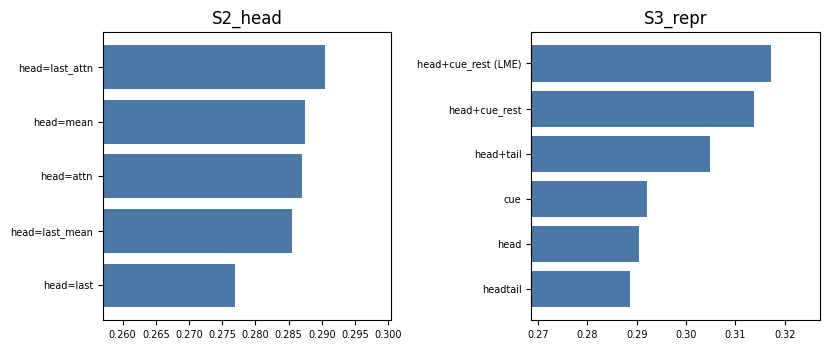

In [18]:
store = load_store()
allx = pd.DataFrame([{"name": n, "views": "+".join(e["rc"]["views"]), "agg": e["rc"]["view_agg"], "head": e["rc"]["head"], "loss": e["rc"]["loss"],
                      "enc_lr": e["rc"]["enc_lr"], "macro_F1@global": e["macro_f1_global"], "macro_AP": e["macro_ap"],
                      "macro_F1 per-label(CV)": e["macro_f1_perlabel_cv"], "micro_F1": e["micro_f1"], "train_min": e["train_minutes"],
                      "docs/s": e["train_docs_per_s"], "peak_GiB": e["peak_gib"]} for n, e in store.items()]).sort_values("macro_F1@global", ascending=False)
display(allx.round(4).reset_index(drop=True)); allx.to_csv(RUN_DIR / "all_experiments.csv", index=False)
try:
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1, len(STAGE_TABLES), figsize=(4.2 * max(1, len(STAGE_TABLES)), 3.6), squeeze=False)
    for ax, (k, df) in zip(axes[0], STAGE_TABLES.items()):
        d = df.sort_values("macro_F1@global"); ax.barh(d["variant"].str.replace("views=", "", regex=False).str.replace(" | chunk-logit LME", " (LME)", regex=False), d["macro_F1@global"], color="#4c78a8")
        ax.set_title(k); ax.set_xlim(max(0, d["macro_F1@global"].min() - 0.02), d["macro_F1@global"].max() + 0.01); ax.tick_params(labelsize=7)
    plt.tight_layout(); plt.show()
except Exception as e: print("plot skipped:", e)

### 13c. Decoder-specific read-out: does the closing-token state help?

In [19]:
if "S2_head" in STAGE_TABLES:
    t = STAGE_TABLES["S2_head"].set_index("variant")
    cols = ["macro_F1@global", "macro_AP", "macro_F1 per-label(CV)", "micro_F1", "macro_R", "macro_P"]
    print("S2 — readout comparison (single 512-token window, 2 epochs, dev subset):"); display(t[cols].round(4))
    def g(h): return t.loc[f"head={h}", "macro_F1@global"] if f"head={h}" in t.index else float("nan")
    print(f"last </s> state only vs mean pooling : {g('last') - g('mean'):+.4f} macro-F1")
    print(f"last </s> state only vs attn pooling : {g('last') - g('attn'):+.4f}")
    print(f"concat(last, attn) vs attn alone     : {g('last_attn') - g('attn'):+.4f}   <- value added by the closing-token state")
    print(f"concat(last, attn) vs last alone     : {g('last_attn') - g('last'):+.4f}   <- value added by attention pooling")
    print(f"concat(last, attn) vs concat(last, mean): {g('last_attn') - g('last_mean'):+.4f}")
else:
    print("S2 was not run in this session.")

S2 — readout comparison (single 512-token window, 2 epochs, dev subset):


,macro_F1@global,macro_AP,macro_F1 per-label(CV),micro_F1,macro_R,macro_P
variant,,,,,,
head=last_attn,0.2905,0.2567,0.2939,0.3920,0.3698,0.2496
head=mean,0.2875,0.2475,0.2920,0.3859,0.3903,0.2378
head=attn,0.2870,0.2518,0.2911,0.3881,0.3614,0.2488
head=last_mean,0.2856,0.2508,0.2913,0.3898,0.3696,0.2445
head=last,0.2770,0.2430,0.2822,0.3876,0.3478,0.2459


last </s> state only vs mean pooling : -0.0105 macro-F1
last </s> state only vs attn pooling : -0.0100
concat(last, attn) vs attn alone     : +0.0035   <- value added by the closing-token state
concat(last, attn) vs last alone     : +0.0135   <- value added by attention pooling
concat(last, attn) vs concat(last, mean): +0.0049


## 14. S4 — post-hoc experiments on the winning model (no training needed)

analysing dev logits of: S3:views=head+cue_rest (3000, 100)


,strategy,macro_f1,micro_f1,macro_precision,macro_recall,subset_acc,avg_pred,empty_rate,seconds
0,per-label raw + top1,0.3213,0.4085,0.3037,0.3793,0.0223,5.8490,0.0000,0.5829
1,per-label shrunk(100) + top1,0.3186,0.4200,0.2833,0.3853,0.0263,5.5713,0.0000,0.5774
2,per-label shrunk(300) + top1,0.3168,0.4203,0.2794,0.3878,0.0253,5.5287,0.0000,0.5692
3,Platt -> per-label shrunk(100),0.3138,0.4337,0.2903,0.3616,0.0250,5.4897,0.0000,1.2047
4,global + top1,0.3137,0.4169,0.2756,0.3870,0.0270,5.4177,0.0000,0.2997
5,global,0.3132,0.4170,0.2765,0.3847,0.0250,5.3760,0.0417,0.2883
6,stacker -> per-label shrunk(100),0.3115,0.4338,0.2965,0.3451,0.0213,5.2403,0.0000,10.7324
7,temperature -> global,0.3110,0.4143,0.2709,0.3882,0.0253,5.4930,0.0000,0.9330
8,stacker -> global,0.3064,0.4364,0.2814,0.3620,0.0113,6.0930,0.0000,10.2443
9,Platt -> global,0.3011,0.4254,0.2643,0.3796,0.0110,6.7463,0.0000,0.9358


,calibrator,ECE,Brier,macro_AP
0,raw,0.05443,0.03901,0.29983
1,temperature,0.03938,0.03797,0.29983
2,per-label Platt,0.00188,0.02774,0.29983
3,stacker (co-occurrence),0.00432,0.02800,0.28546


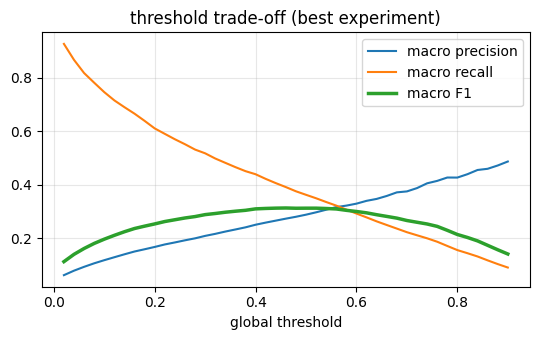


strongest statute co-occurrences in train (lift = observed/expected, count >= 50):
  statutes 20 & 28: lift  65.8  (together in 451 docs)
  statutes 15 & 16: lift  53.0  (together in 277 docs)
  statutes 29 & 49: lift  50.3  (together in 222 docs)
  statutes 49 & 50: lift  50.2  (together in 142 docs)
  statutes 29 & 50: lift  44.4  (together in 164 docs)
  statutes 64 & 86: lift  42.5  (together in 228 docs)
  statutes 23 & 25: lift  39.2  (together in 80 docs)
  statutes 29 & 36: lift  37.0  (together in 245 docs)
  statutes 21 & 47: lift  31.4  (together in 442 docs)
  statutes 21 & 53: lift  30.9  (together in 630 docs)
mean labels/doc = 3.70; docs with >=5 labels: 30.9%


In [20]:
best_entry = [e for e in load_store().values() if e["rc_key"] == rc_key(BEST_RC)]
best_entry = best_entry[0] if best_entry else max(load_store().values(), key=lambda e: e["macro_f1_global"])
z_best = np.load(logits_path(best_entry["name"])); y_best = Y_dev_sub
print("analysing dev logits of:", best_entry["name"], z_best.shape)

def strategy_table(y, z, K=5):
    rows, preds = [], {}
    for name, fn in STRATEGIES.items():
        t0 = time.time(); pr = crossfit(y, z, fn, K=K); preds[name] = pr
        rows.append(dict(strategy=name, **prf_summary(y, pr), seconds=time.time() - t0))
    return pd.DataFrame(rows).sort_values("macro_f1", ascending=False).reset_index(drop=True), preds

S4_TABLE, S4_PREDS = strategy_table(y_best, z_best)
display(S4_TABLE.round(4))

# calibration quality (fit on one half, measure on the other)
h = len(z_best) // 2; zc_tr, zc_te, yc_tr, yc_te = z_best[:h], z_best[h:], y_best[:h], y_best[h:]
cal_rows = []
for nm, tf in [("raw", lambda q: q), ("temperature", fit_temperature(yc_tr, zc_tr)), ("per-label Platt", fit_platt(yc_tr, zc_tr)), ("stacker (co-occurrence)", fit_stacker(yc_tr, zc_tr))]:
    e_, b_ = ece_brier(yc_te, sigmoid(tf(zc_te))); cal_rows.append(dict(calibrator=nm, ECE=e_, Brier=b_, macro_AP=macro_ap(yc_te, sigmoid(tf(zc_te)))))
display(pd.DataFrame(cal_rows).round(5))

# precision / recall trade-off of one global threshold
try:
    import matplotlib.pyplot as plt
    ths = np.round(np.arange(0.02, 0.91, 0.02), 2); P, R, Fm = [], [], []
    for t in ths:
        s = prf_summary(y_best, (sigmoid(z_best) >= t).astype(np.uint8)); P.append(s["macro_precision"]); R.append(s["macro_recall"]); Fm.append(s["macro_f1"])
    plt.figure(figsize=(5.5, 3.5)); plt.plot(ths, P, label="macro precision"); plt.plot(ths, R, label="macro recall"); plt.plot(ths, Fm, label="macro F1", lw=2.5)
    plt.xlabel("global threshold"); plt.legend(); plt.grid(alpha=.3); plt.title("threshold trade-off (best experiment)"); plt.tight_layout(); plt.show()
except Exception as e: print("plot skipped:", e)

# label co-occurrence structure in the training labels
co = (Ytr.T.astype(np.float64) @ Ytr.astype(np.float64)); marg = np.diag(co).copy(); np.fill_diagonal(co, 0)
lift = co * len(Ytr) / np.maximum(np.outer(marg, marg), 1)
pairs = sorted([(lift[i, j], co[i, j], i, j) for i in range(NUM_LABELS) for j in range(i + 1, NUM_LABELS) if co[i, j] >= 50], reverse=True)[:10]
print("\nstrongest statute co-occurrences in train (lift = observed/expected, count >= 50):")
for l, c, i, j in pairs: print(f"  statutes {i:>2d} & {j:>2d}: lift {l:5.1f}  (together in {int(c)} docs)")
print(f"mean labels/doc = {Ytr.sum(1).mean():.2f}; docs with >=5 labels: {(Ytr.sum(1)>=5).mean()*100:.1f}%")

## 15. FINAL TRAINING — best recipe, full training set, early stopping

In [23]:
FINAL_RC = dict(BEST_RC); FINAL_RC["views"] = tuple(FINAL_RC["views"])
FINAL_BEST_PT, FINAL_LAST_PT = RUN_DIR / "final_best.pt", RUN_DIR / "final_last.pt"
FINAL_DEV_LOGITS = RUN_DIR / "final_best_dev_logits.npy"; FINAL_HISTORY = RUN_DIR / "final_history.json"

final_train_idx = np.arange(Ntr) if FINAL_TRAIN_DOCS_LIMIT is None else np.sort(np.random.default_rng(SEED).permutation(Ntr)[:FINAL_TRAIN_DOCS_LIMIT])
final_dev_idx = np.arange(Ndv) if FINAL_TRAIN_DOCS_LIMIT is None else np.arange(min(Ndv, 512))
Y_final_dev = Ydv[final_dev_idx]

dps = best_entry["train_docs_per_s"]; edps = best_entry["eval_docs_per_s"]
est_epoch_s = len(final_train_idx) / dps + len(final_dev_idx) / edps
planned_epochs = int(max(1, min(FINAL_MAX_EPOCHS, (FINAL_TIME_BUDGET_H * 3600) // est_epoch_s)))
if SMOKE_TEST: planned_epochs = FINAL_MAX_EPOCHS
print("final recipe:", json.dumps(rc_norm(FINAL_RC)))
print(f"estimated {est_epoch_s/60:.0f} min / epoch  ->  planned epochs = {planned_epochs} (max {FINAL_MAX_EPOCHS}, patience {FINAL_PATIENCE})")

seed_everything(SEED)
final_model = build_model(FINAL_RC)
FT = build_training(final_model, FINAL_RC, len(final_train_idx), planned_epochs)
final_train_ds = LSIDataset("train", final_train_idx, FINAL_RC["views"]); final_dev_ds = LSIDataset("dev", final_dev_idx, FINAL_RC["views"])

history, best_f1, best_epoch, bad, start_epoch = [], -1.0, 0, 0, 1
if RESUME_FINAL and FINAL_LAST_PT.exists():
    ck = torch.load(FINAL_LAST_PT, map_location="cpu", weights_only=False)
    final_model.load_state_dict(ck["model"]); FT["opt"].load_state_dict(ck["opt"]); FT["sched"].load_state_dict(ck["sched"]); FT["scaler"].load_state_dict(ck["scaler"])
    history, best_f1, best_epoch, bad, start_epoch = ck["history"], ck["best_f1"], ck["best_epoch"], ck["bad"], ck["epoch"] + 1
    del ck; print(f"resumed after epoch {start_epoch-1}; best so far {best_f1:.4f} (epoch {best_epoch})")

run_start = time.time()
for epoch in range(start_epoch, planned_epochs + 1):
    ep0 = time.time()
    tr_loss, d = train_one_epoch(final_model, make_loader(final_train_ds, FT["mb"], True, SEED + epoch), FT, tag=f"final ep{epoch}/{planned_epochs}", log_frac=0.1)
    z_dev, _ = predict_logits(final_model, final_dev_ds, FT["mb"] * 2)
    m = evaluate_logits(Y_final_dev, z_dev)
    rec = dict(epoch=epoch, train_loss=tr_loss, **{k: m[k] for k in ["macro_f1_global", "best_global_thr", "macro_ap", "macro_f1_perlabel_cv", "micro_f1", "subset_acc", "macro_precision", "macro_recall", "bce"]},
               epoch_minutes=(time.time() - ep0) / 60); history.append(rec)
    print(f"\n=== epoch {epoch}: train loss {tr_loss:.4f} | dev macro-F1 {m['macro_f1_global']:.4f} @thr {m['best_global_thr']:.2f} | per-label(CV) {m['macro_f1_perlabel_cv']:.4f} | "
          f"macro-AP {m['macro_ap']:.4f} | micro-F1 {m['micro_f1']:.4f} | {rec['epoch_minutes']:.1f} min ===\n")
    if m["macro_f1_global"] > best_f1 + 1e-4:
        best_f1, best_epoch, bad = m["macro_f1_global"], epoch, 0
        torch.save({"model_state_dict": {k: v.detach().cpu() for k, v in final_model.state_dict().items()}, "epoch": epoch, "dev_macro_f1_global": best_f1}, FINAL_BEST_PT)
        np.save(FINAL_DEV_LOGITS, z_dev.astype(np.float32)); print(f"   new best epoch {epoch} saved -> {FINAL_BEST_PT}")
    else:
        bad += 1; print(f"   no improvement ({bad}/{FINAL_PATIENCE})")
    json.dump(history, open(FINAL_HISTORY, "w"), indent=1)
    torch.save({"model": final_model.state_dict(), "opt": FT["opt"].state_dict(), "sched": FT["sched"].state_dict(), "scaler": FT["scaler"].state_dict(),
                "history": history, "best_f1": best_f1, "best_epoch": best_epoch, "bad": bad, "epoch": epoch}, FINAL_LAST_PT)
    if bad >= FINAL_PATIENCE: print("early stopping."); break
print(f"\nfinal training finished: best epoch {best_epoch}, dev macro-F1 {best_f1:.4f}, wall time {(time.time()-run_start)/3600:.2f} h (this session)")
display(pd.DataFrame(history).round(4))

final recipe: {"views": ["head", "cue_rest"], "view_agg": "tokens", "head": "last_attn", "loss": "bce_posw", "enc_lr": 0.0001, "head_lr": 0.001, "llrd": 0.92, "wd": 0.01, "dropout": 0.1, "warmup": 0.06}
estimated 51 min / epoch  ->  planned epochs = 6 (max 6, patience 2)
   final ep1/6 534/5344 | loss 0.4554 | 14.9 docs/s
   final ep1/6 1068/5344 | loss 0.4060 | 14.9 docs/s
   final ep1/6 1602/5344 | loss 0.3860 | 14.9 docs/s
   final ep1/6 2136/5344 | loss 0.3746 | 14.9 docs/s
   final ep1/6 2670/5344 | loss 0.3651 | 14.9 docs/s
   final ep1/6 3204/5344 | loss 0.3575 | 14.9 docs/s
   final ep1/6 3738/5344 | loss 0.3510 | 14.9 docs/s
   final ep1/6 4272/5344 | loss 0.3450 | 14.9 docs/s
   final ep1/6 4806/5344 | loss 0.3402 | 14.9 docs/s
   final ep1/6 5340/5344 | loss 0.3357 | 14.9 docs/s
   final ep1/6 5344/5344 | loss 0.3356 | 14.9 docs/s

=== epoch 1: train loss 0.3356 | dev macro-F1 0.3230 @thr 0.48 | per-label(CV) 0.3466 | macro-AP 0.3136 | micro-F1 0.4328 | 51.4 min ===

   new 

,epoch,train_loss,macro_f1_global,best_global_thr,macro_ap,macro_f1_perlabel_cv,micro_f1,subset_acc,macro_precision,macro_recall,bce,epoch_minutes
0,1,0.3356,0.3230,0.48,0.3136,0.3466,0.4328,0.0166,0.3249,0.4057,0.1479,51.3859
1,2,0.2494,0.3677,0.57,0.3514,0.3815,0.4567,0.0384,0.3549,0.4351,0.1438,51.3858
2,3,0.1631,0.3802,0.43,0.3603,0.3895,0.4775,0.0451,0.3581,0.4299,0.1153,51.4199
3,4,0.0871,0.3907,0.45,0.3623,0.3931,0.4885,0.0523,0.3837,0.4168,0.1265,51.4195
4,5,0.0420,0.3895,0.40,0.3631,0.3931,0.4925,0.0711,0.4144,0.3819,0.1412,51.4079
5,6,0.0169,0.3878,0.23,0.3609,0.3890,0.4910,0.0718,0.3966,0.3915,0.1615,51.3927


## 16. Reload the best epoch, choose the post-processing on dev (out-of-fold), predict the test set, write `submission.json` + the final `.pt`

In [27]:
ck = torch.load(FINAL_BEST_PT, map_location="cpu", weights_only=False)
final_model.load_state_dict(ck["model_state_dict"]); final_model.eval(); best_epoch = ck["epoch"]; del ck
z_dev_final = np.load(FINAL_DEV_LOGITS); assert z_dev_final.shape == Y_final_dev.shape

POST_TABLE, POST_PREDS = strategy_table(Y_final_dev, z_dev_final, K=5)
print("post-processing options, out-of-fold on the full dev set:"); display(POST_TABLE.round(4))
POST_NAME = POST_TABLE.iloc[0]["strategy"]
post_predictor = STRATEGIES[POST_NAME](Y_final_dev, z_dev_final)         # refit on ALL dev documents
dev_oof_pred = POST_PREDS[POST_NAME]
print(f"\nchosen post-processing: {POST_NAME} | out-of-fold dev macro-F1 {POST_TABLE.iloc[0]['macro_f1']:.4f} | micro-F1 {POST_TABLE.iloc[0]['micro_f1']:.4f} | subset acc {POST_TABLE.iloc[0]['subset_acc']:.4f}")
base_row = POST_TABLE[POST_TABLE.strategy == "global"].iloc[0]
print(f"(plain global threshold would give macro-F1 {base_row['macro_f1']:.4f})")

# ---------------- test inference ----------------
test_ds = LSIDataset("test", np.arange(Nte), FINAL_RC["views"], with_labels=False)
t0 = time.time(); z_test, test_dps = predict_logits(final_model, test_ds, FT["mb"] * 2); infer_s = time.time() - t0
np.save(RUN_DIR / "test_logits.npy", z_test.astype(np.float32)); print(f"test inference: {Nte:,} docs in {infer_s/60:.1f} min ({test_dps:.1f} docs/s)")
test_pred = post_predictor(z_test)

# ---------------- submission ----------------
def write_submission(case_ids, pred_bin, path):
    out = []
    for i, cid in enumerate(case_ids):
        labs = sorted({int(j) for j in np.flatnonzero(pred_bin[i])})
        out.append({"id": cid, "pred": labs})
    assert len(out) == len(case_ids) == len({json.dumps(c) for c in case_ids}), "one unique object per test document"
    for o in out:
        assert all(isinstance(x, int) and 0 <= x < NUM_LABELS for x in o["pred"]) and len(o["pred"]) == len(set(o["pred"]))
    json.dump(out, open(path, "w")); return out

test_ids = ARR["test"]["ids"]
submission = write_submission(test_ids, test_pred, RUN_DIR / "submission.json")
if ON_KAGGLE: write_submission(test_ids, test_pred, WORK / "submission.json")
n_lab = np.array([len(o["pred"]) for o in submission])
print(f"submission written: {len(submission):,} objects | labels/doc mean {n_lab.mean():.2f}, min {n_lab.min()}, max {n_lab.max()} | empty {int((n_lab==0).sum())}")
print("first 3:", submission[:3]); print("train mean labels/doc for reference: %.2f" % Ytr.sum(1).mean())

# ---------------- final .pt (weights + everything needed to reproduce the predictions) ----------------
FINAL_PT = RUN_DIR / "lsi_gqa_full_ft_final.pt"
post = dict(name=POST_NAME, thresholds=np.asarray(post_predictor.thr).tolist(), calibrator=post_predictor.tf.params, ensure_at_least_one_label=True)
best_state = torch.load(FINAL_BEST_PT, map_location="cpu", weights_only=False)["model_state_dict"]
torch.save({"model_state_dict": best_state, "recipe": rc_norm(FINAL_RC), "model_config": asdict(cfg), "num_labels": NUM_LABELS, "label_ids": list(range(NUM_LABELS)),
            "best_epoch": best_epoch, "dev_metrics_best_epoch": history[best_epoch - 1] if history else None, "postprocess": post,
            "dev_oof_macro_f1_after_postprocess": float(POST_TABLE.iloc[0]["macro_f1"]), "max_seq_len": MAX_LEN, "content_tokens_per_view": CONTENT,
            "tokenizer_path": str(PHASE1_TOKENIZER_PATH), "phase1_checkpoint": str(PHASE1_CHECKPOINT_PATH), "experiment_3": "phase1 GQA decoder-only LM + full fine-tuning (last </s> state + attention pooling)", "window_format": "[</s>] + text + [</s>]"}, FINAL_PT)
del best_state; gc.collect()
print(f"final model saved: {FINAL_PT} ({FINAL_PT.stat().st_size/1024**2:.0f} MB)")
if ON_KAGGLE: print("also copy to /kaggle/working top level if needed:", WORK)

post-processing options, out-of-fold on the full dev set:


,strategy,macro_f1,micro_f1,macro_precision,macro_recall,subset_acc,avg_pred,empty_rate,seconds
0,stacker -> per-label shrunk(100),0.3952,0.4982,0.4042,0.3980,0.0590,4.4711,0.0000,35.7772
1,per-label shrunk(100) + top1,0.3947,0.4899,0.3949,0.4085,0.0564,4.5808,0.0000,2.1556
2,per-label raw + top1,0.3940,0.4881,0.4030,0.4027,0.0561,4.5667,0.0000,2.1729
3,per-label shrunk(300) + top1,0.3930,0.4901,0.3892,0.4112,0.0570,4.6239,0.0000,2.1797
4,stacker -> global,0.3916,0.5029,0.3961,0.4024,0.0537,4.6977,0.0000,36.6732
5,global,0.3907,0.4885,0.3837,0.4168,0.0523,4.7377,0.0287,1.0899
6,global + top1,0.3901,0.4882,0.3814,0.4178,0.0532,4.7664,0.0000,1.1119
7,temperature -> global,0.3892,0.4877,0.3810,0.4163,0.0533,4.7522,0.0000,3.5587
8,Platt -> per-label shrunk(100),0.3768,0.4338,0.4073,0.3903,0.0060,5.5695,0.0000,4.9519
9,Platt -> global,0.3679,0.4391,0.3949,0.4029,0.0051,6.4894,0.0000,3.9599



chosen post-processing: stacker -> per-label shrunk(100) | out-of-fold dev macro-F1 0.3952 | micro-F1 0.4982 | subset acc 0.0590
(plain global threshold would give macro-F1 0.3907)
test inference: 13,019 docs in 4.6 min (47.2 docs/s)
submission written: 13,019 objects | labels/doc mean 4.42, min 1, max 25 | empty 0
first 3: [{'id': '100002997', 'pred': [5, 34, 37, 94]}, {'id': '100004477', 'pred': [5, 71, 81, 94]}, {'id': '1000086', 'pred': [5, 34]}]
train mean labels/doc for reference: 3.70
final model saved: /kaggle/working/lsi_gqa_runs/lsi_gqa_full_ft_final.pt (532 MB)
also copy to /kaggle/working top level if needed: /kaggle/working


In [29]:
!ls -lh /kaggle/working/submission.json /kaggle/working/lsi_gqa_runs/submission.json /kaggle/working/lsi_gqa_runs/lsi_gqa_full_ft_final.pt

-rw-r--r-- 1 root root 533M Oct 27 10:33 /kaggle/working/lsi_gqa_runs/lsi_gqa_full_ft_final.pt
-rw-r--r-- 1 root root 599K Oct 27 10:33 /kaggle/working/lsi_gqa_runs/submission.json
-rw-r--r-- 1 root root 599K Oct 27 10:33 /kaggle/working/submission.json


In [30]:
import os
from IPython.display import FileLink, display
os.chdir("/kaggle/working")                       # FileLink needs paths relative to the working directory

display(FileLink("submission.json"))
display(FileLink("lsi_gqa_runs/lsi_gqa_full_ft_final.pt"))

/kaggle/working/submission.json

/kaggle/working/lsi_gqa_runs/lsi_gqa_full_ft_final.pt

## 17. Analysis for the report (§10.5)

In [28]:
y, pr = Y_final_dev, dev_oof_pred                   # out-of-fold predictions after the chosen post-processing
f1 = label_f1(y, pr); sup_tr = Ytr.sum(0); sup_dv = y.sum(0)
yb, pb = y.astype(bool), pr.astype(bool); tp = (yb & pb).sum(0); fp = (~yb & pb).sum(0); fn = (yb & ~pb).sum(0)
per_label = pd.DataFrame({"statute": np.arange(NUM_LABELS), "train_support": sup_tr, "dev_support": sup_dv, "precision": tp / np.maximum(tp + fp, 1),
                          "recall": tp / np.maximum(tp + fn, 1), "f1": f1, "FP": fp, "FN": fn})
per_label.to_csv(RUN_DIR / "final_per_label_metrics.csv", index=False)
per_label["support_quartile"] = pd.qcut(per_label["train_support"].rank(method="first"), 4, labels=["rarest 25%", "rare-mid", "common-mid", "most common 25%"])
print("macro-F1 by statute frequency (how rare statutes affect performance):"); display(per_label.groupby("support_quartile", observed=True)[["f1", "precision", "recall"]].mean().round(3))
print("worst statutes:"); display(per_label.sort_values("f1").head(12).round(3).reset_index(drop=True))
print("best statutes:");  display(per_label.sort_values("f1", ascending=False).head(8).round(3).reset_index(drop=True))
print("correlation between statute frequency and F1: %.3f" % np.corrcoef(np.log(sup_tr), f1)[0, 1])

# confusion: statute j missed (FN) in documents where statute k was predicted without being true
M = (yb & ~pb).T.astype(np.int64) @ (~yb & pb).astype(np.int64); np.fill_diagonal(M, 0)
top = np.dstack(np.unravel_index(np.argsort(-M.ravel())[:12], M.shape))[0]
print("\nmost common 'missed j while spurious k predicted' pairs:")
for j, k in top: print(f"  missed {j:>2d} / predicted-instead {k:>2d}: {M[j,k]:4d} docs   (train co-occurrence lift of the pair: {lift[j,k]:.1f})")
corr = np.corrcoef(np.log1p(M).ravel(), np.log1p(co).ravel())[0, 1]; print(f"confusion pairs vs. train co-occurrence correlation: {corr:.3f}")

# experiment comparison + cost
store = load_store(); rows = []
for n, e in store.items():
    rows.append({"experiment": n, "macro_F1@global": e["macro_f1_global"], "macro_AP": e["macro_ap"], "trainable_params_M": e["params_trainable"] / 1e6,
                 "train_docs/s": e["train_docs_per_s"], "eval_docs/s": e["eval_docs_per_s"], "peak_GPU_GiB": e["peak_gib"], "train_min": e["train_minutes"]})
cost = pd.DataFrame(rows).sort_values("macro_F1@global", ascending=False)
n_params_final = sum(p.numel() for p in final_model.parameters())
print(f"\nfinal model: {n_params_final/1e6:.1f} M parameters (all trainable), fp32 checkpoint {FINAL_PT.stat().st_size/1024**2:.0f} MB, "
      f"test inference {test_dps:.1f} docs/s, views per document = {len(FINAL_RC['views'])}")
display(cost.round(3).head(20).reset_index(drop=True))

# automatic headline summary
print("\n================ SUMMARY FOR THE REPORT ================")
for stage, df in STAGE_TABLES.items():
    d = df.sort_values("macro_F1@global", ascending=False); b, w = d.iloc[0], d.iloc[-1]
    print(f"{stage:9s}: best '{b['variant']}' {b['macro_F1@global']:.4f}  | worst '{w['variant']}' {w['macro_F1@global']:.4f} | spread {b['macro_F1@global']-w['macro_F1@global']:.4f}")
print(f"post-processing: global {base_row['macro_f1']:.4f} -> '{POST_NAME}' {POST_TABLE.iloc[0]['macro_f1']:.4f} (out-of-fold, full dev)")
print(f"final dev macro-F1 at best epoch ({best_epoch}), single global threshold: {best_f1:.4f}; exp-1 reference (Phase 1 encoder + full FT): 0.3826")

macro-F1 by statute frequency (how rare statutes affect performance):


,f1,precision,recall
support_quartile,,,
rarest 25%,0.283,0.313,0.267
rare-mid,0.382,0.420,0.355
common-mid,0.399,0.406,0.400
most common 25%,0.517,0.478,0.570


worst statutes:


,statute,train_support,dev_support,precision,recall,f1,FP,FN,support_quartile
0,8,349,92,0.130,0.033,0.052,20,89,rarest 25%
1,0,343,86,0.158,0.070,0.097,32,80,rarest 25%
2,2,367,98,0.205,0.092,0.127,35,89,rarest 25%
3,52,1084,272,0.180,0.118,0.142,146,240,common-mid
4,32,385,99,0.157,0.141,0.149,75,85,rarest 25%
5,40,543,152,0.158,0.151,0.154,123,129,rare-mid
6,76,530,142,0.202,0.127,0.156,71,124,rare-mid
7,99,674,176,0.220,0.153,0.181,96,149,rare-mid
8,3,453,113,0.193,0.204,0.198,96,90,rarest 25%
9,7,1037,260,0.204,0.196,0.200,199,209,common-mid


best statutes:


,statute,train_support,dev_support,precision,recall,f1,FP,FN,support_quartile
0,28,602,151,0.866,0.815,0.840,19,28,rare-mid
1,34,10380,2596,0.784,0.828,0.805,591,447,most common 25%
2,20,487,122,0.790,0.770,0.780,25,28,rare-mid
3,81,1321,346,0.794,0.725,0.758,65,95,common-mid
4,94,3835,958,0.707,0.693,0.700,275,294,most common 25%
5,36,569,142,0.676,0.648,0.662,44,50,rare-mid
6,29,497,125,0.688,0.616,0.650,35,48,rare-mid
7,5,11730,2936,0.564,0.735,0.638,1670,779,most common 25%


correlation between statute frequency and F1: 0.527

most common 'missed j while spurious k predicted' pairs:
  missed 39 / predicted-instead 43:  166 docs   (train co-occurrence lift of the pair: 1.6)
  missed 14 / predicted-instead  5:  153 docs   (train co-occurrence lift of the pair: 0.9)
  missed 12 / predicted-instead  5:  144 docs   (train co-occurrence lift of the pair: 0.7)
  missed 39 / predicted-instead  5:  132 docs   (train co-occurrence lift of the pair: 1.4)
  missed 97 / predicted-instead  5:  125 docs   (train co-occurrence lift of the pair: 1.1)
  missed 13 / predicted-instead  5:  125 docs   (train co-occurrence lift of the pair: 0.7)
  missed  5 / predicted-instead 43:  117 docs   (train co-occurrence lift of the pair: 1.5)
  missed 44 / predicted-instead 43:  116 docs   (train co-occurrence lift of the pair: 2.8)
  missed 39 / predicted-instead 97:  115 docs   (train co-occurrence lift of the pair: 1.2)
  missed 10 / predicted-instead  5:  111 docs   (train co-occu

,experiment,macro_F1@global,macro_AP,trainable_params_M,train_docs/s,eval_docs/s,peak_GPU_GiB,train_min
0,S3:views=head+cue_rest | chunk-logit LME,0.317,0.281,139.439,14.947,47.114,7.750,17.968
1,S3:views=head+cue_rest,0.314,0.281,139.439,14.928,46.987,7.749,17.991
2,S3:views=head+tail,0.305,0.276,139.439,14.921,47.190,7.749,17.999
3,S3:views=cue,0.292,0.255,139.439,28.746,94.116,7.749,9.343
4,S2:head=last_attn,0.290,0.257,139.439,28.761,93.409,7.749,9.338
5,S3:views=headtail,0.289,0.255,139.439,28.775,92.134,7.749,9.334
6,S2:head=mean,0.287,0.248,139.166,29.121,93.048,7.748,9.223
7,S2:head=attn,0.287,0.252,139.363,28.801,93.052,7.749,9.325
8,S2:head=last_mean,0.286,0.251,139.242,28.864,93.096,7.744,9.305
9,S2:head=last,0.277,0.243,139.166,29.047,93.419,7.748,9.246



================ SUMMARY FOR THE REPORT ================
S2_head  : best 'head=last_attn' 0.2905  | worst 'head=last' 0.2770 | spread 0.0135
S3_repr  : best 'views=head+cue_rest | chunk-logit LME' 0.3171  | worst 'views=headtail' 0.2886 | spread 0.0285
post-processing: global 0.3907 -> 'stacker -> per-label shrunk(100)' 0.3952 (out-of-fold, full dev)
final dev macro-F1 at best epoch (4), single global threshold: 0.3907; exp-1 reference (Phase 1 encoder + full FT): 0.3826


### Files to download from `/kaggle/working/lsi_gqa_runs/`
`lsi_gqa_full_ft_final.pt` (the model) · `submission.json` · `experiments.json` · `best_recipe.json` · `final_history.json` · `final_best_dev_logits.npy`